# **Análise de sinais de vibração de drones**
Equipe: Ana Maria Cunha, Mateus Ferreira Borges e Arthur Britto

In [ ]:
!gdown --id 1l0AScHDbsGFCsKA72q3DCv4ZPBvyh-WW -O /content/datasetSinais.zip

!unzip -q /content/datasetSinais.zip -d  /content/dados/

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1l0AScHDbsGFCsKA72q3DCv4ZPBvyh-WW
From (redirected): https://drive.google.com/uc?id=1l0AScHDbsGFCsKA72q3DCv4ZPBvyh-WW&confirm=t&uuid=74602c1a-659e-401b-9fb0-7e76d96faf38
To: /content/datasetSinais.zip
100% 501M/501M [00:09<00:00, 55.0MB/s]


In [ ]:
import os, glob, json, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from scipy.io import loadmat

## **1. Seleção e preparação dos dados**
### **1.1 Exploração dos arquivos**

In [ ]:
from scipy.io import whosmat

# lista com o caminho de todos os .mat, procurando em todas as subpastas
arquivos = sorted(glob.glob('/content/dados/**/*.mat', recursive=True))
print('Total de arquivos:', len(arquivos))

# whosmat lista as variáveis de cada arquivo e o formato EXATO delas, sem carregar os dados
inventario = pd.DataFrame([
    {'arquivo': os.path.basename(c).replace('.mat', ''),
     **{nome: str(formato) for nome, formato, _ in whosmat(c)}}
    for c in arquivos])

# quantos arquivos têm cada variável
print('\nQuantos arquivos contêm cada variável:')
print(inventario.drop(columns='arquivo').notna().sum())

# quais arquivos NÃO têm IMUData
print('\nArquivos sem IMUData:')
print(inventario.loc[inventario['IMUData'].isna(), 'arquivo'].tolist() if 'IMUData' in inventario else 'todos')

Total de arquivos: 111

Quantos arquivos contêm cada variável:
AccData        111
IMUData        108
BatteryVolt    108
dtype: int64

Arquivos sem IMUData:
['F0_SV0_SP0_C4_R1', 'F0_SV0_SP0_C4_R2', 'F0_SV0_SP0_C4_R3']


In [ ]:
# primeiro arquivo que tem IMUData
exemplo = next(c for c in arquivos if any(n == 'IMUData' for n, _, _ in whosmat(c)))
print('Arquivo:', os.path.basename(exemplo), '\n')

d = loadmat(exemplo)                                   # SEM squeeze_me
for nome, formato, tipo in whosmat(exemplo):
    print(f'{nome}: {tipo} {formato}')
    if tipo == 'struct':
        s = d[nome][0, 0]
        for campo in s.dtype.names:
            print(f'    {campo}: {s[campo].shape}')

Arquivo: F0_SV0_SP1_C1_R1.mat 

AccData: struct (1, 1)
    DATE: (1,)
    samplingRate: (1, 1)
    t: (1, 600000)
    Vib_Data: (1, 600000)
IMUData: struct (1, 1)
    t: (1, 82344)
    Vib_Data: (3, 82344)
    samplingRate: (1, 1)
BatteryVolt: double (1, 82344)


In [ ]:
d = loadmat(exemplo, squeeze_me=True, struct_as_record=False)
imu = d['IMUData'].Vib_Data                            # (3, N)
for i, eixo in enumerate(['x', 'y', 'z']):
    print(f'eixo {eixo}: média = {imu[i].mean():7.3f} | desvio = {imu[i].std():.3f}')

acc = d['AccData'].Vib_Data
print(f'\npiezo (AccData): média = {acc.mean():.4f} | desvio = {acc.std():.4f}')

eixo x: média =   0.031 | desvio = 0.679
eixo y: média =  -0.201 | desvio = 0.812
eixo z: média =   9.718 | desvio = 1.090

piezo (AccData): média = -0.0010 | desvio = 0.0444


In [ ]:
linhas = []
for caminho in arquivos:
    nome = os.path.basename(caminho).replace('.mat', '')
    d = loadmat(caminho, squeeze_me=True, struct_as_record=False)

    partes = nome.split('_')
    partes = partes + [None] * (5 - len(partes))       # arquivos danificados não têm a parte R
    F, SV, SP, C, R = partes

    acc = d['AccData']
    linha = {
        'arquivo': nome, 'F': F, 'SV': SV, 'SP': SP, 'C': C, 'R': R,
        'data': acc.DATE,
        # piezo
        'acc_fs': acc.samplingRate,
        'acc_n_amostras': acc.Vib_Data.size,
        'acc_duracao_s': acc.Vib_Data.size / acc.samplingRate,
        # IMU
        'tem_imu': 'IMUData' in d,
        'tem_bateria': 'BatteryVolt' in d,
        'caminho': caminho,
    }
    if 'IMUData' in d:
        imu = d['IMUData']
        linha.update({
            'imu_fs': imu.samplingRate,
            'imu_eixos': imu.Vib_Data.shape[0],
            'imu_n_amostras': imu.Vib_Data.shape[1],
            'imu_duracao_s': imu.Vib_Data.shape[1] / imu.samplingRate,
        })
    linhas.append(linha)

tabela = pd.DataFrame(linhas)
tabela['condicao'] = np.where(tabela['F'] == 'F0', 'saudavel', 'danificada')
tabela['tipo_falha'] = tabela['F'].map({'F0': 'nenhuma', 'F1': 'grupo 1', 'F2': 'grupo 2', 'F3': 'grupo 3'})
tabela.drop(columns='caminho')

,arquivo,F,SV,SP,C,R,data,acc_fs,acc_n_amostras,acc_duracao_s,tem_imu,tem_bateria,imu_fs,imu_eixos,imu_n_amostras,imu_duracao_s,condicao,tipo_falha
0,F0_SV0_SP0_C4_R1,F0,SV0,SP0,C4,R1,30-Sep-2024,10000,1200000,120.0,False,False,NaN,NaN,NaN,NaN,saudavel,nenhuma
1,F0_SV0_SP0_C4_R2,F0,SV0,SP0,C4,R2,12-Nov-2024,10000,1200000,120.0,False,False,NaN,NaN,NaN,NaN,saudavel,nenhuma
2,F0_SV0_SP0_C4_R3,F0,SV0,SP0,C4,R3,29-Sep-2024,10000,1200000,120.0,False,False,NaN,NaN,NaN,NaN,saudavel,nenhuma
3,F0_SV0_SP1_C1_R1,F0,SV0,SP1,C1,R1,25-Sep-2024,10000,600000,60.0,True,True,1000.0,3.0,82344.0,82.344,saudavel,nenhuma
4,F0_SV0_SP1_C1_R2,F0,SV0,SP1,C1,R2,11-Nov-2024,10000,600000,60.0,True,True,1000.0,3.0,94846.0,94.846,saudavel,nenhuma
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,F3_SV3_SP2_C2,F3,SV3,SP2,C2,None,25-Sep-2024,10000,600000,60.0,True,True,1000.0,3.0,80757.0,80.757,danificada,grupo 3
107,F3_SV3_SP2_C3,F3,SV3,SP2,C3,None,29-Sep-2024,10000,200000,20.0,True,True,1000.0,3.0,32586.0,32.586,danificada,grupo 3
108,F3_SV3_SP3_C1,F3,SV3,SP3,C1,None,25-Sep-2024,10000,600000,60.0,True,True,1000.0,3.0,81033.0,81.033,danificada,grupo 3
109,F3_SV3_SP3_C2,F3,SV3,SP3,C2,None,25-Sep-2024,10000,600000,60.0,True,True,1000.0,3.0,81325.0,81.325,danificada,grupo 3


In [ ]:
tabela[['acc_fs', 'acc_duracao_s', 'imu_fs', 'imu_duracao_s']].describe()

,acc_fs,acc_duracao_s,imu_fs,imu_duracao_s
count,111.0,111.000000,108.0,108.000000
mean,10000.0,50.810811,1000.0,68.468167
std,0.0,21.197561,0.0,22.260201
min,10000.0,20.000000,1000.0,31.916000
25%,10000.0,20.000000,1000.0,35.055000
50%,10000.0,60.000000,1000.0,80.882000
75%,10000.0,60.000000,1000.0,81.736750
max,10000.0,120.000000,1000.0,94.846000


In [ ]:
# a duração do piezo e da IMU é a mesma em cada arquivo?
tabela['dif_duracao_s'] = tabela['imu_duracao_s'] - tabela['acc_duracao_s']
tabela.groupby(['SP', 'C'])[['acc_duracao_s', 'imu_duracao_s', 'dif_duracao_s']].mean().round(1)

acc_duracao_s  imu_duracao_s  dif_duracao_s
SP  C                                              
SP0 C4          120.0            NaN            NaN
SP1 C1           60.0           83.0           23.0
    C2           60.0           82.9           22.9
    C3           26.7           42.3           15.7
SP2 C1           60.0           82.2           22.2
    C2           60.0           81.3           21.3
    C3           26.7           40.7           14.0
SP3 C1           60.0           81.6           21.6
    C2           60.0           81.7           21.7
    C3           26.7           40.6           14.0

In [113]:
import hashlib

def impressao_digital(caminho):
    # código único gerado a partir dos valores do sinal: sinais idênticos -> códigos idênticos
    d = loadmat(caminho, squeeze_me=True, struct_as_record=False)
    return hashlib.md5(d['AccData'].Vib_Data.tobytes()).hexdigest()

tabela['id_sinal'] = tabela['caminho'].map(impressao_digital)

# 1) quantas gravações diferentes existem
print('Arquivos:', len(tabela), '| gravações diferentes:', tabela['id_sinal'].nunique())

# 2) tabela com todos os arquivos que têm sinal repetido
dup = tabela[tabela.duplicated('id_sinal', keep=False)]
grupos = (dup.groupby('id_sinal')
             .agg(arquivos=('arquivo', ' = '.join),
                  condicao=('condicao', lambda s: ', '.join(sorted(s.unique()))),
                  velocidades=('SP', lambda s: ', '.join(sorted(s.unique()))),
                  repeticoes=('R', lambda s: ', '.join(sorted(s.unique()))),
                  canais=('C', lambda s: ', '.join(sorted(s.unique()))))
             .reset_index(drop=True))
print(f'\n{len(grupos)} grupos de arquivos com sinais idênticos:')

print('Todas as duplicatas são de registros saudáveis?', (dup['condicao'] == 'saudavel').all())
print('Há duplicatas entre registros danificados?',
      tabela.loc[tabela['condicao'] == 'danificada', 'id_sinal'].duplicated().any())
print('Canais envolvidos nas duplicatas:', sorted(dup['C'].unique()))
print('Em cada grupo, os arquivos têm a mesma velocidade e a mesma repetição?',
      ((dup.groupby('id_sinal')['SP'].nunique() == 1) & (dup.groupby('id_sinal')['R'].nunique() == 1)).all())

saud_c3 = tabela[(tabela['condicao'] == 'saudavel') & (tabela['C'] == 'C3')]
print('Algum registro saudável do canal C3 tem sinal repetido?', saud_c3['id_sinal'].isin(dup['id_sinal']).any())

Arquivos: 111 | gravações diferentes: 102

9 grupos de arquivos com sinais idênticos:
Todas as duplicatas são de registros saudáveis? True
Há duplicatas entre registros danificados? False
Canais envolvidos nas duplicatas: ['C1', 'C2']
Em cada grupo, os arquivos têm a mesma velocidade e a mesma repetição? True
Algum registro saudável do canal C3 tem sinal repetido? False


In [114]:
print(grupos.to_string())

                              arquivos  condicao velocidades repeticoes  canais
0  F0_SV0_SP3_C1_R1 = F0_SV0_SP3_C2_R1  saudavel         SP3         R1  C1, C2
1  F0_SV0_SP3_C1_R2 = F0_SV0_SP3_C2_R2  saudavel         SP3         R2  C1, C2
2  F0_SV0_SP1_C1_R3 = F0_SV0_SP1_C2_R3  saudavel         SP1         R3  C1, C2
3  F0_SV0_SP2_C1_R1 = F0_SV0_SP2_C2_R1  saudavel         SP2         R1  C1, C2
4  F0_SV0_SP2_C1_R3 = F0_SV0_SP2_C2_R3  saudavel         SP2         R3  C1, C2
5  F0_SV0_SP2_C1_R2 = F0_SV0_SP2_C2_R2  saudavel         SP2         R2  C1, C2
6  F0_SV0_SP3_C1_R3 = F0_SV0_SP3_C2_R3  saudavel         SP3         R3  C1, C2
7  F0_SV0_SP1_C1_R2 = F0_SV0_SP1_C2_R2  saudavel         SP1         R2  C1, C2
8  F0_SV0_SP1_C1_R1 = F0_SV0_SP1_C2_R1  saudavel         SP1         R1  C1, C2


**Resultado:** dos 111 arquivos, apenas 102 contêm gravações diferentes. Os 9 grupos de sinais idênticos são todos formados por registros **saudáveis** dos canais **C1 e C2**, com a mesma velocidade e a mesma repetição (ex.: `F0_SV0_SP1_C1_R1` = `F0_SV0_SP1_C2_R1`), cobrindo as três velocidades (SP1, SP2 e SP3) e as três repetições (R1, R2 e R3). Não há duplicatas entre registros danificados, e nenhum registro saudável do canal C3 é repetido. Ou seja, a mesma gravação saudável de referência é usada nos canais C1 e C2. Por isso, as análises são feitas **em um único canal**: juntar C1 e C2 contaria a mesma gravação saudável duas vezes.

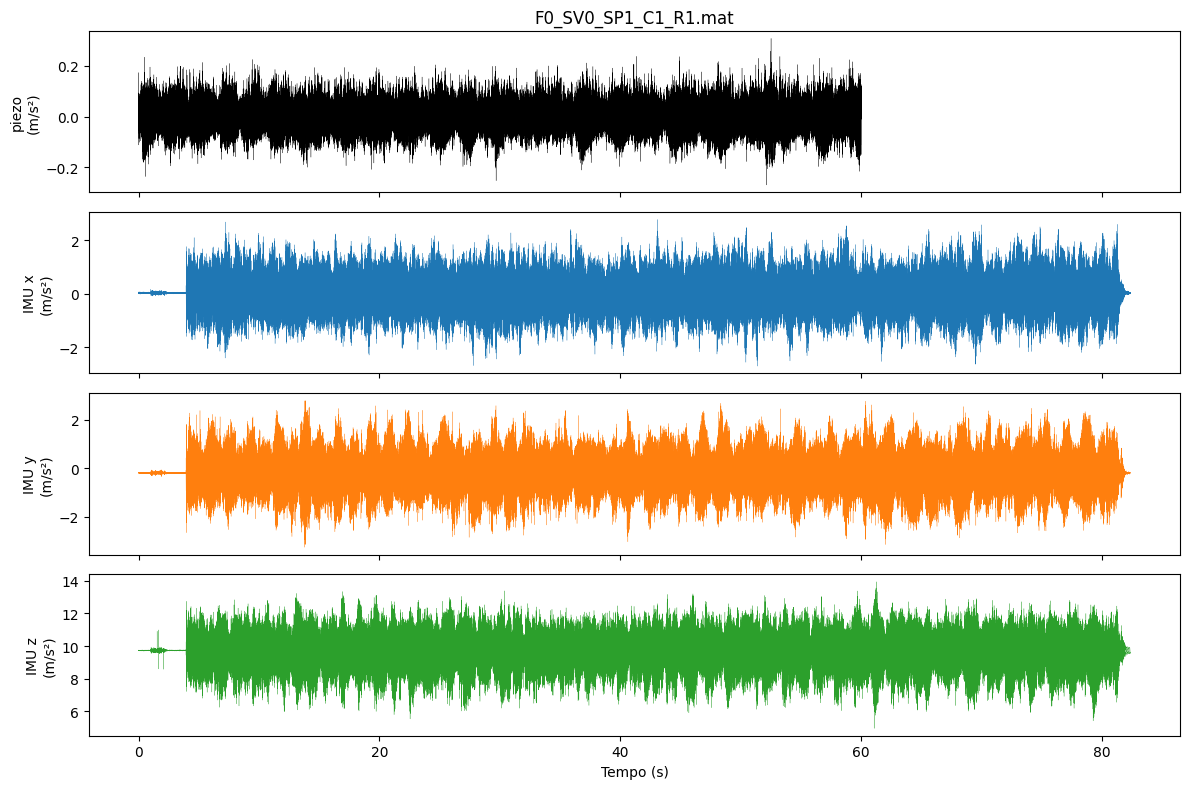

In [ ]:
d = loadmat(exemplo, squeeze_me=True, struct_as_record=False)
acc, imu = d['AccData'], d['IMUData']

fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
axs[0].plot(acc.t, acc.Vib_Data, lw=0.2, color='k')
axs[0].set_ylabel('piezo\n(m/s²)'); axs[0].set_title(os.path.basename(exemplo))
for i, eixo in enumerate(['x', 'y', 'z']):
    axs[i+1].plot(imu.t, imu.Vib_Data[i], lw=0.2, color=f'C{i}')
    axs[i+1].set_ylabel(f'IMU {eixo}\n(m/s²)')
axs[-1].set_xlabel('Tempo (s)'); plt.tight_layout(); plt.show()

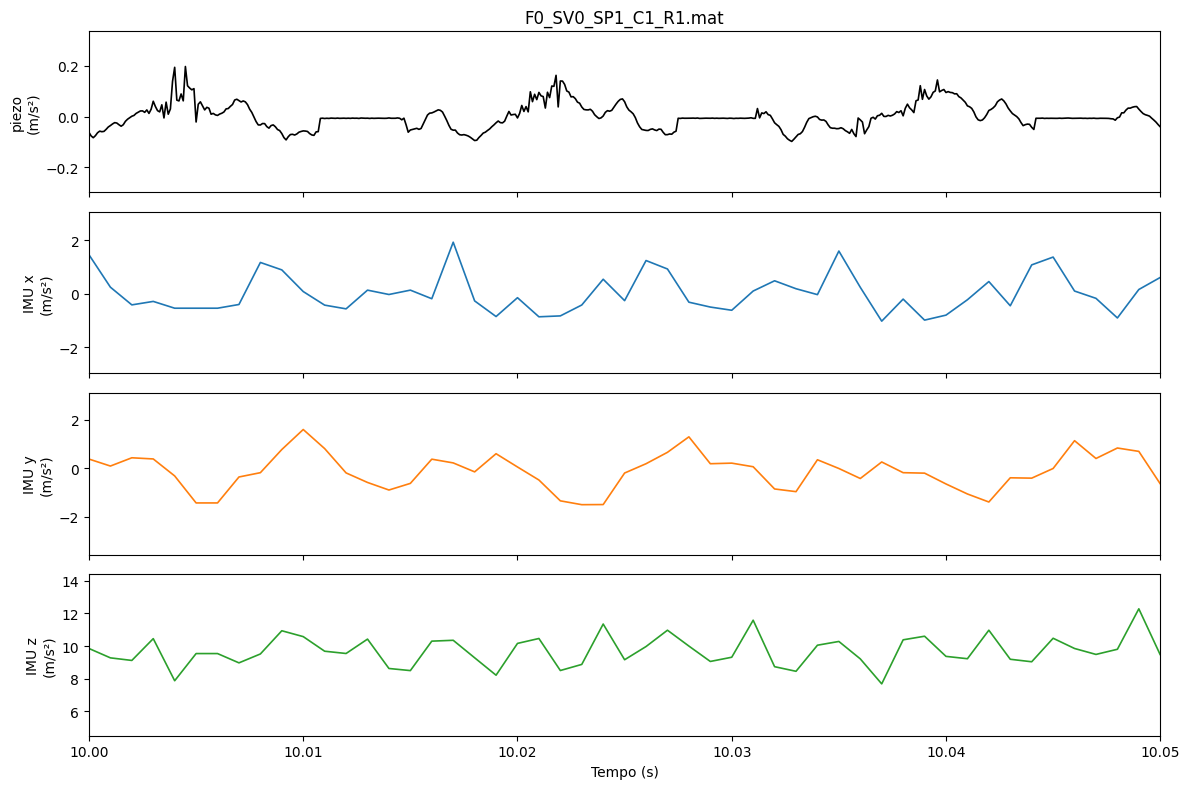

In [ ]:
d = loadmat(exemplo, squeeze_me=True, struct_as_record=False)
acc, imu = d['AccData'], d['IMUData']

T_MIN = 10.00
T_MAX = 10.05

fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

axs[0].plot(acc.t, acc.Vib_Data, lw=1.2, color='k')
axs[0].set_ylabel('piezo\n(m/s²)'); axs[0].set_title(os.path.basename(exemplo))

for i, eixo in enumerate(['x', 'y', 'z']):
    axs[i+1].plot(imu.t, imu.Vib_Data[i], lw=1.2, color=f'C{i}')
    axs[i+1].set_ylabel(f'IMU {eixo}\n(m/s²)')

axs[-1].set_xlabel('Tempo (s)')
axs[-1].set_xlim(T_MIN, T_MAX)

plt.tight_layout()
plt.show()

### **Resumo da estrutura dos arquivos**

| Variável | Conteúdo | Formato | Taxa | Unidade |
|---|---|---|---|---|
| `AccData.Vib_Data` | acelerômetro piezoelétrico, 1 eixo | (1, N) | 10 000 Hz | m/s² (informado pela monitoria) |
| `IMUData.Vib_Data` | acelerômetro da IMU, 3 eixos (linhas = x, y, z) | (3, N) | 1 000 Hz | m/s² (confirmado pela gravidade: média ≈ 9,8 no eixo z) |
| `BatteryVolt` | tensão da bateria | (1, N) | 1 000 Hz | V |


- Nome dos arquivos: `F{falha}_SV{severidade}_SP{velocidade}_C{C}[_R{repetição}]`, conforme a nomenclatura do DronePropA (mesmos autores). F0/SV0 = hélice saudável; F1–F3 = grupos de falha; SV1–SV3 = severidade; R só existe quando o experimento foi repetido.
- Não há informações sobre o que é o código **C**. Como há possibilidade que se refira a configurações diferentes do drone, serão comparados experimentos com o mesmo C.
- Os arquivos SP0 + C4 contêm apenas o piezo e só a condição saudável.
- No mesmo arquivo, piezo e IMU têm durações diferentes (ex.: 60 s e ~82 s), então os dois sensores não são comparados instante a instante.

### **1.2 Seleção dos Registros**

In [ ]:
pd.crosstab([tabela['SP'], tabela['C']], [tabela['F'], tabela['SV']])

F       F0  F1          F2          F3        
SV     SV0 SV1 SV2 SV3 SV1 SV2 SV3 SV1 SV2 SV3
SP  C                                         
SP0 C4   3   0   0   0   0   0   0   0   0   0
SP1 C1   3   1   1   1   1   1   1   1   1   1
    C2   3   1   1   1   1   1   1   1   1   1
    C3   3   1   1   1   1   1   1   1   1   1
SP2 C1   3   1   1   1   1   1   1   1   1   1
    C2   3   1   1   1   1   1   1   1   1   1
    C3   3   1   1   1   1   1   1   1   1   1
SP3 C1   3   1   1   1   1   1   1   1   1   1
    C2   3   1   1   1   1   1   1   1   1   1
    C3   3   1   1   1   1   1   1   1   1   1

In [ ]:
# segundos de sinal por condição, para cada combinação (piezo e IMU)
resumo = (tabela[tabela['SP'] != 'SP0']
          .groupby(['SP', 'C', 'condicao'])[['acc_duracao_s', 'imu_duracao_s']].sum().unstack())
resumo

acc_duracao_s          imu_duracao_s         
condicao    danificada saudavel    danificada saudavel
SP  C                                                 
SP1 C1           540.0    180.0       732.180  263.311
    C2           540.0    180.0       732.006  263.311
    C3           180.0    140.0       301.622  206.241
SP2 C1           540.0    180.0       740.582  245.280
    C2           540.0    180.0       730.065  245.280
    C3           180.0    140.0       292.115  196.234
SP3 C1           540.0    180.0       731.045  248.042
    C2           540.0    180.0       731.780  248.042
    C3           180.0    140.0       291.904  195.522

In [ ]:
SP_ESCOLHIDO, C_ESCOLHIDO = 'SP3', 'C1'
sel = tabela[(tabela['SP'] == SP_ESCOLHIDO) & (tabela['C'] == C_ESCOLHIDO)].copy()
print('Todos os registros selecionados têm IMU?', sel['tem_imu'].all())
sel.groupby('condicao')[['acc_duracao_s', 'imu_duracao_s']].sum()

Todos os registros selecionados têm IMU? True


,acc_duracao_s,imu_duracao_s
condicao,,
danificada,540.0,731.045
saudavel,180.0,248.042


In [ ]:
linhas = []
for _, r in sel.iterrows():
    base = {'arquivo': r['arquivo'], 'condicao': r['condicao'], 'tipo_falha': r['tipo_falha'],
            'severidade': r['SV'], 'repeticao': r['R'], 'velocidade': r['SP'], 'c': r['C']}
    linhas.append({**base, 'sensor': 'piezo (AccData)', 'eixo': 'único', 'unidade': 'm/s²',
                   'fs_Hz': r['acc_fs'], 'duracao_s': r['acc_duracao_s'], 'n_amostras': r['acc_n_amostras'],
                   'uso': 'análise principal'})
    if r['tem_imu']:
        for eixo in ['x', 'y', 'z']:
            linhas.append({**base, 'sensor': 'IMU (IMUData)', 'eixo': eixo, 'unidade': 'm/s²',
                           'fs_Hz': r['imu_fs'], 'duracao_s': r['imu_duracao_s'], 'n_amostras': r['imu_n_amostras'],
                           'uso': 'investigação adicional'})

tabela_registros = pd.DataFrame(linhas)
tabela_registros

,arquivo,condicao,tipo_falha,severidade,repeticao,velocidade,canal,sensor,eixo,unidade,fs_Hz,duracao_s,n_amostras,uso
0,F0_SV0_SP3_C1_R1,saudavel,nenhuma,SV0,R1,SP3,C1,piezo (AccData),único,m/s²,10000.0,60.000,600000.0,análise principal
1,F0_SV0_SP3_C1_R1,saudavel,nenhuma,SV0,R1,SP3,C1,IMU (IMUData),x,m/s²,1000.0,81.709,81709.0,investigação adicional
2,F0_SV0_SP3_C1_R1,saudavel,nenhuma,SV0,R1,SP3,C1,IMU (IMUData),y,m/s²,1000.0,81.709,81709.0,investigação adicional
3,F0_SV0_SP3_C1_R1,saudavel,nenhuma,SV0,R1,SP3,C1,IMU (IMUData),z,m/s²,1000.0,81.709,81709.0,investigação adicional
4,F0_SV0_SP3_C1_R2,saudavel,nenhuma,SV0,R2,SP3,C1,piezo (AccData),único,m/s²,10000.0,60.000,600000.0,análise principal
5,F0_SV0_SP3_C1_R2,saudavel,nenhuma,SV0,R2,SP3,C1,IMU (IMUData),x,m/s²,1000.0,84.400,84400.0,investigação adicional
6,F0_SV0_SP3_C1_R2,saudavel,nenhuma,SV0,R2,SP3,C1,IMU (IMUData),y,m/s²,1000.0,84.400,84400.0,investigação adicional
7,F0_SV0_SP3_C1_R2,saudavel,nenhuma,SV0,R2,SP3,C1,IMU (IMUData),z,m/s²,1000.0,84.400,84400.0,investigação adicional
8,F0_SV0_SP3_C1_R3,saudavel,nenhuma,SV0,R3,SP3,C1,piezo (AccData),único,m/s²,10000.0,60.000,600000.0,análise principal
9,F0_SV0_SP3_C1_R3,saudavel,nenhuma,SV0,R3,SP3,C1,IMU (IMUData),x,m/s²,1000.0,81.933,81933.0,investigação adicional


In [ ]:
# (sensor da análise principal = piezo)
tabela_final = pd.DataFrame({
    'Registro':       sel['arquivo'],
    'Condição':       sel['condicao'],
    'Falha':          sel['tipo_falha'],
    'Severidade':     sel['SV'],
    'Repetição':      sel['R'].fillna('-'),
    'Velocidade':     sel['SP'],
    'C':          sel['C'],
    'Sensor':         'piezo (AccData)',
    'Eixo':           'único',
    'Unidade':        'm/s²',
    'fs (Hz)':        sel['acc_fs'],
    'Duração (s)':    sel['acc_duracao_s'],
    'Nº de amostras': sel['acc_n_amostras'],
}).reset_index(drop=True)
tabela_final

,Registro,Condição,Falha,Severidade,Repetição,Velocidade,Canal,Sensor,Eixo,Unidade,fs (Hz),Duração (s),Nº de amostras
0,F0_SV0_SP3_C1_R1,saudavel,nenhuma,SV0,R1,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
1,F0_SV0_SP3_C1_R2,saudavel,nenhuma,SV0,R2,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
2,F0_SV0_SP3_C1_R3,saudavel,nenhuma,SV0,R3,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
3,F1_SV1_SP3_C1,danificada,grupo 1,SV1,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
4,F1_SV2_SP3_C1,danificada,grupo 1,SV2,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
5,F1_SV3_SP3_C1,danificada,grupo 1,SV3,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
6,F2_SV1_SP3_C1,danificada,grupo 2,SV1,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
7,F2_SV2_SP3_C1,danificada,grupo 2,SV2,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
8,F2_SV3_SP3_C1,danificada,grupo 2,SV3,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000
9,F3_SV1_SP3_C1,danificada,grupo 3,SV1,-,SP3,C1,piezo (AccData),único,m/s²,10000,60.0,600000


In [ ]:
criterios = {
    'Velocidade (SP)':          sel['SP'],
    'C':                        sel['C'],
    'Sensor':                   pd.Series('piezo (AccData)', index=sel.index),
    'Eixo':                     pd.Series('único', index=sel.index),
    'Unidade':                  pd.Series('m/s²', index=sel.index),
    'Frequência de amostragem': sel['acc_fs'],
    'Duração (s)':              sel['acc_duracao_s'],
    'Condição da hélice':       sel['condicao'],
    'Tipo de falha':            sel['tipo_falha'],
    'Severidade':               sel['SV'],
}
comparabilidade = pd.DataFrame([
    {'Característica': nome,
     'Valores nos registros selecionados': ', '.join(map(str, sorted(col.dropna().unique()))),
     'Igual em todos?': 'sim' if col.nunique() == 1 else 'NÃO (varia)'}
    for nome, col in criterios.items()])
comparabilidade

,Característica,Valores nos registros selecionados,Igual em todos?
0,Velocidade (SP),SP3,sim
1,Canal (C),C1,sim
2,Sensor,piezo (AccData),sim
3,Eixo,único,sim
4,Unidade,m/s²,sim
5,Frequência de amostragem,10000,sim
6,Duração (s),60.0,sim
7,Condição da hélice,"danificada, saudavel",NÃO (varia)
8,Tipo de falha,"grupo 1, grupo 2, grupo 3, nenhuma",NÃO (varia)
9,Severidade,"SV0, SV1, SV2, SV3",NÃO (varia)


**Justificativa:** os 12 registros selecionados têm a mesma velocidade (SP3), o mesmo C (C1), o mesmo sensor (piezo), a mesma taxa de amostragem (10 kHz) e a mesma duração (60 s). Eles diferem apenas na condição da hélice: 3 repetições saudáveis (F0) e 9 danificadas (3 grupos de falha × 3 severidades). Assim, as diferenças observadas podem ser atribuídas à condição da hélice, e não às condições de operação. O drone não é identificado nos nomes dos arquivos do DronePropB. Como já mencionado, como não há informações sobre do que se trata o código C, selecionamos arquivos com o mesmo C, para evitar a possibilidade de comparações equívocas.

**Escolha do sensor:** a análise principal usa o **piezo** (`AccData`) porque:
(i) embora os dois sensores registrem as mesmas componentes principais (~135, ~270 e ~400 Hz; ver seção 5.1), o piezo, com taxa de 10 kHz (Nyquist = 5 kHz), representa todo o conteúdo espectral observado, inclusive componentes acima de 500 Hz, enquanto a IMU (1 kHz, Nyquist = 500 Hz) se limita a 500 Hz e apresenta energia próxima desse limite compatível com aliasing de componentes de frequência mais alta;
(ii) tem duração uniforme (60 s) em todos os registros selecionados e começa com os motores já em regime, enquanto a IMU tem duração variável (≈ 81 a 95 s) e inicia a gravação antes de os motores entrarem em regime, o que exigiu descartar janelas (seção 5.2);
(iii) não registra a componente constante da gravidade nem apresentou deriva, podendo ser analisado sem nenhum tratamento, ao passo que a IMU precisa de filtragem para remover a gravidade (média de ≈ 9,7 m/s² no eixo z; seção 2.4);
(iv) é descrito pelos autores do dataset como o acelerômetro de alta sensibilidade acrescentado especificamente para os ensaios em solo; e
(v) mede um único eixo.
Os três eixos da IMU são analisados na investigação adicional (seção 5).

### **1.3 Verificação dos Dados**

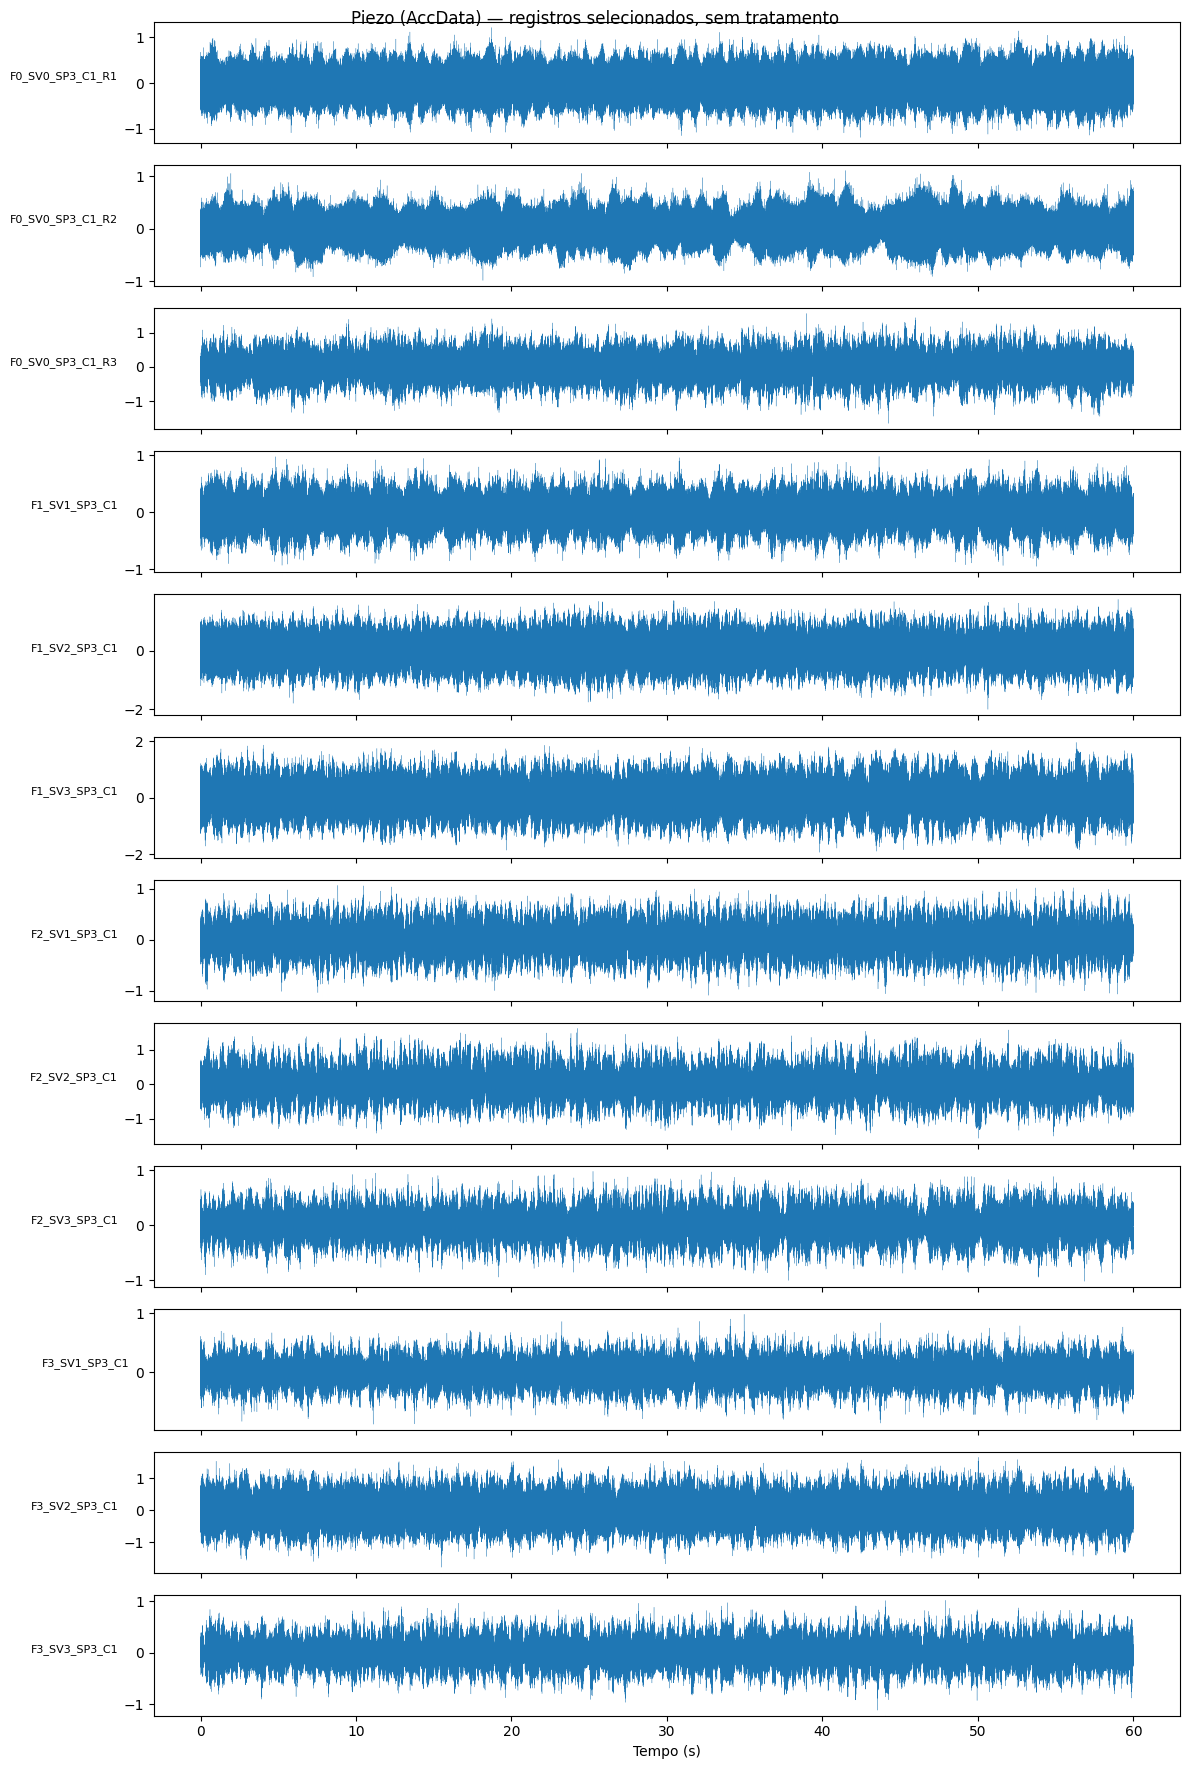

/tmp/ipykernel_3105/699137065.py:17: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  ax.set_title('Linha de base de cada registro'); ax.legend(fontsize=6, ncol=3); plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


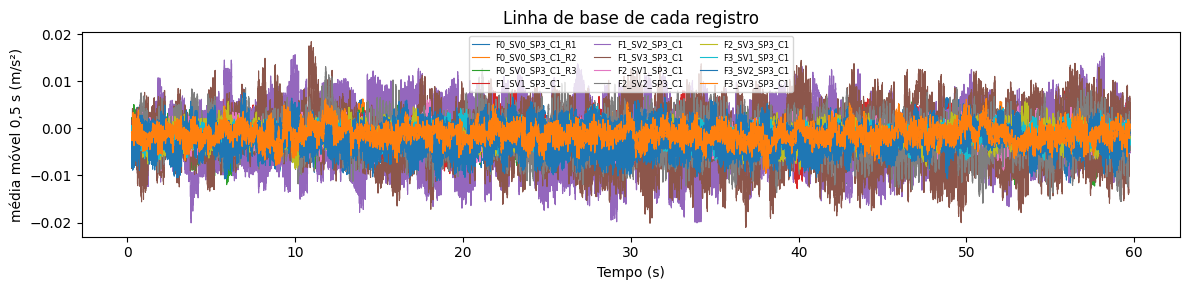

In [ ]:
fig, axs = plt.subplots(len(sel), 1, figsize=(12, 1.5 * len(sel)), sharex=True)
axs = np.atleast_1d(axs)
for ax, (_, linha) in zip(axs, sel.iterrows()):
    acc = loadmat(linha['caminho'], squeeze_me=True, struct_as_record=False)['AccData']
    ax.plot(acc.t, acc.Vib_Data, lw=0.2)
    ax.set_ylabel(linha['arquivo'], rotation=0, ha='right', fontsize=8)
axs[-1].set_xlabel('Tempo (s)'); plt.suptitle('Piezo (AccData) — registros selecionados, sem tratamento')
plt.tight_layout(); plt.show()

# deriva lenta: média móvel de 0,5 s de cada registro
fig, ax = plt.subplots(figsize=(12, 3))
for _, linha in sel.iterrows():
    acc = loadmat(linha['caminho'], squeeze_me=True, struct_as_record=False)['AccData']
    centro = pd.Series(acc.Vib_Data).rolling(5000, center=True).mean()
    ax.plot(acc.t, centro, lw=0.8, label=linha['arquivo'])
ax.set_xlabel('Tempo (s)'); ax.set_ylabel('média móvel 0,5 s (m/s²)')
ax.set_title('Linha de base de cada registro'); ax.legend(fontsize=6, ncol=3); plt.tight_layout(); plt.show()

In [65]:
from scipy import signal

FS = 10000                                                      # taxa do piezo (Hz)
assert (sel['acc_fs'] == FS).all(), 'algum registro selecionado não tem fs = 10 kHz'

sinais = {}                                                     # nome do arquivo -> sinal do piezo (sem tratamento)
sinais_brutos = {}                                              # mesmo conteúdo; mantido porque a seção 2.4 usa este nome
for _, linha in sel.iterrows():
    acc = loadmat(linha['caminho'], squeeze_me=True, struct_as_record=False)['AccData']   # piezo
    x = acc.Vib_Data
    print(linha['arquivo'], '| NaN:', np.isnan(x).sum(), '| amostras:', len(x))
    sinais_brutos[linha['arquivo']] = x
    sinais[linha['arquivo']] = x

F0_SV0_SP3_C1_R1 | NaN: 0 | amostras: 600000
F0_SV0_SP3_C1_R2 | NaN: 0 | amostras: 600000
F0_SV0_SP3_C1_R3 | NaN: 0 | amostras: 600000
F1_SV1_SP3_C1 | NaN: 0 | amostras: 600000
F1_SV2_SP3_C1 | NaN: 0 | amostras: 600000
F1_SV3_SP3_C1 | NaN: 0 | amostras: 600000
F2_SV1_SP3_C1 | NaN: 0 | amostras: 600000
F2_SV2_SP3_C1 | NaN: 0 | amostras: 600000
F2_SV3_SP3_C1 | NaN: 0 | amostras: 600000
F3_SV1_SP3_C1 | NaN: 0 | amostras: 600000
F3_SV2_SP3_C1 | NaN: 0 | amostras: 600000
F3_SV3_SP3_C1 | NaN: 0 | amostras: 600000


In [66]:
DUR_JANELA = 1.0                       # segundos
N = int(DUR_JANELA * FS)               # 10000 amostras por janela

janelas = []                           # lista com o sinal de cada janela
info = []                              # informações de cada janela (de onde ela veio)
for _, linha in sel.iterrows():
    x = sinais[linha['arquivo']]
    n_janelas = len(x) // N            # quantas janelas inteiras cabem
    for k in range(n_janelas):
        janelas.append(x[k*N:(k+1)*N])
        info.append({'arquivo': linha['arquivo'], 'condicao': linha['condicao'],
                     'F': linha['F'], 'SV': linha['SV'], 'janela': k})

df_janelas = pd.DataFrame(info)
print(len(janelas), 'janelas de', N, 'amostras')
df_janelas['condicao'].value_counts()

720 janelas de 10000 amostras


,count
condicao,
danificada,540
saudavel,180


**Janelamento (1.3, item 4):** cada sinal do piezo, sem tratamento, foi dividido em janelas de **1 s** (N = 10 000 amostras a fs = 10 kHz), **sem sobreposição**, resultando em 60 janelas por registro: **180 janelas saudáveis** (3 registros) e **540 danificadas** (9 registros). Cada janela guarda o nome do registro de origem (coluna `arquivo`), o que permitirá, na 2ª entrega, separar treino e teste por registro. A duração de 1 s resulta em resolução espectral Δf = fs/N = 1 Hz (ver seção 3.5).

## **2. Análise no Domínio do Tempo**

### **2.1 Gráficos em função do tempo**

In [ ]:
CORES = {'saudavel': 'tab:blue', 'danificada': 'tab:red'}
CORES_F = {'F0': 'tab:blue', 'F1': 'tab:orange', 'F2': 'tab:green', 'F3': 'tab:red'}
ORDEM_ARQ = list(sel.sort_values(['F', 'SV', 'R'])['arquivo'])     # saudáveis primeiro
lim = max(np.max(np.abs(x)) for x in sinais.values())       # mesma escala em todos os gráficos

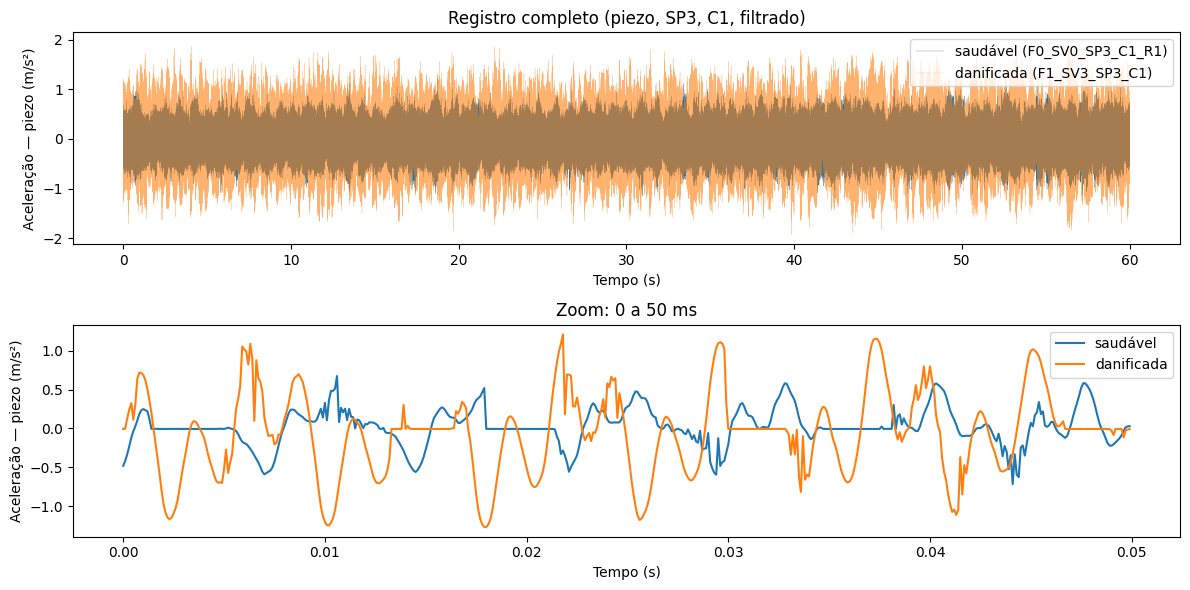

In [67]:
x_s = sinais['F0_SV0_SP3_C1_R1']        # um saudável
x_d = sinais['F1_SV3_SP3_C1']           # um danificado (pode trocar)
t = np.arange(len(x_s)) / FS

fig, axs = plt.subplots(2, 1, figsize=(12, 6))
axs[0].plot(t, x_s, lw=0.2, label='saudável (F0_SV0_SP3_C1_R1)')
axs[0].plot(t[:len(x_d)], x_d, lw=0.2, alpha=0.6, label='danificada (F1_SV3_SP3_C1)')
axs[0].set_title('Registro completo (piezo, SP3, C1, filtrado)')
m = t < 0.05                            # zoom nos primeiros 50 ms
axs[1].plot(t[m], x_s[m], label='saudável'); axs[1].plot(t[m], x_d[m], label='danificada')
axs[1].set_title('Zoom: 0 a 50 ms')
for ax in axs: ax.set_xlabel('Tempo (s)'); ax.set_ylabel('Aceleração — piezo (m/s²)'); ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig('tempo_sinais.pdf'); plt.show()

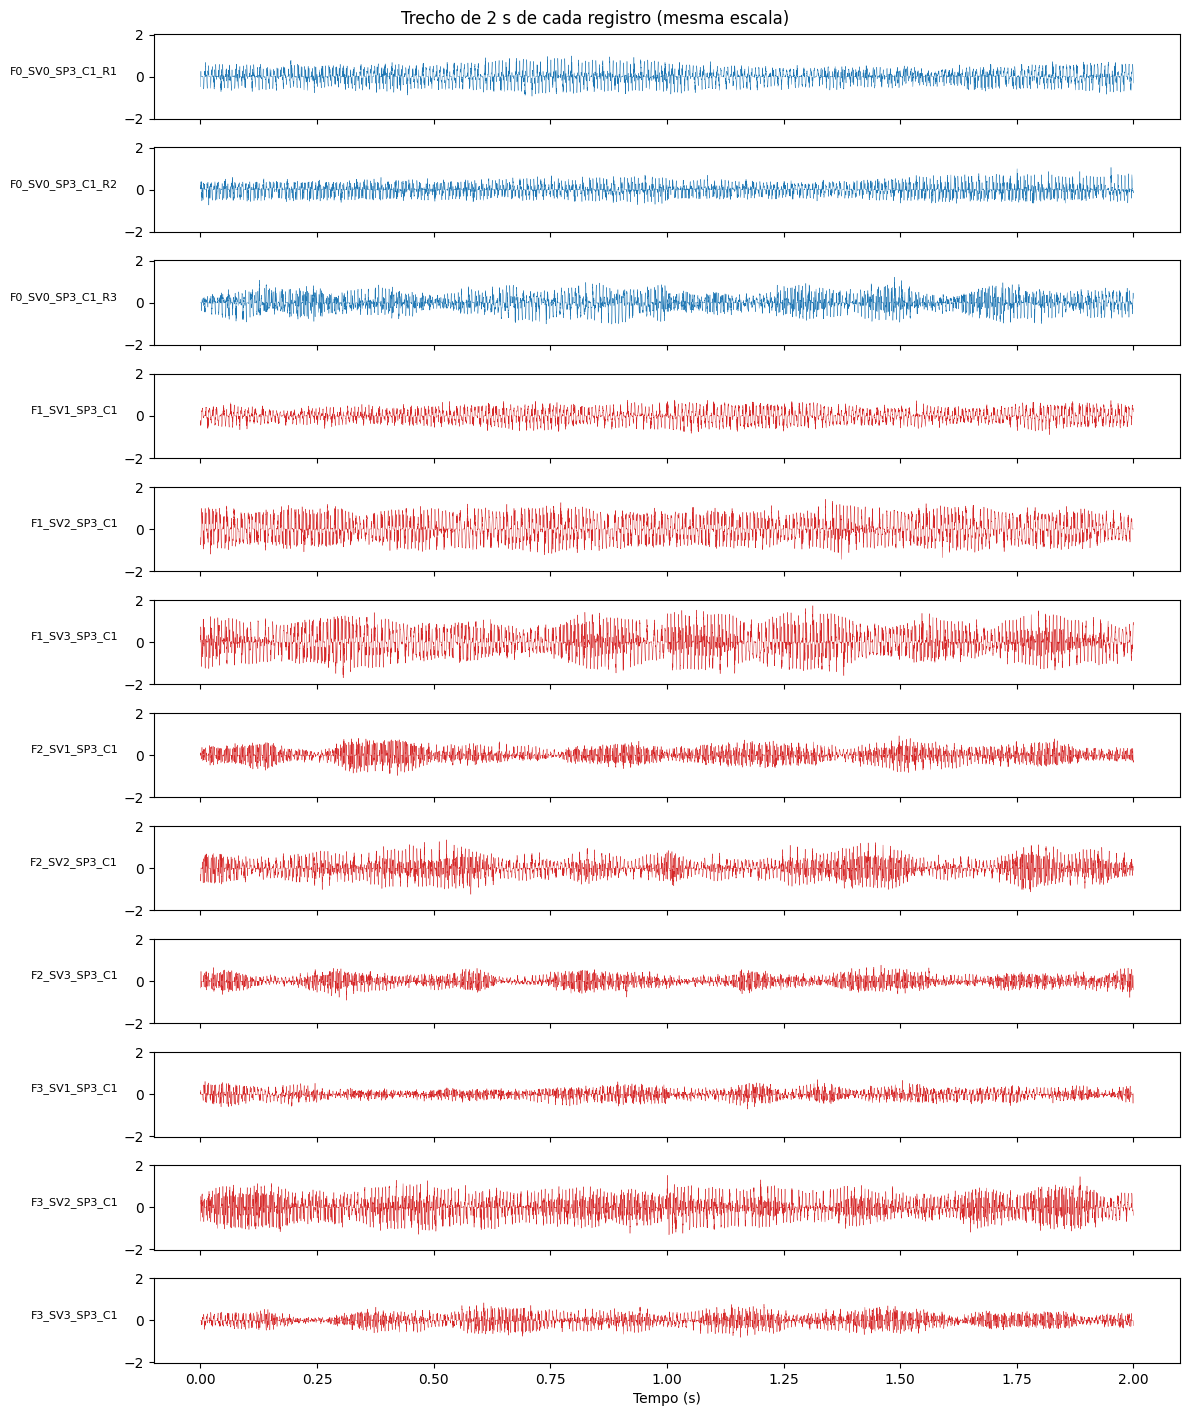

In [68]:
fig, axs = plt.subplots(len(ORDEM_ARQ), 1, figsize=(12, 1.2*len(ORDEM_ARQ)), sharex=True, sharey=True)
for ax, arq in zip(axs, ORDEM_ARQ):
    x = sinais[arq][:2*FS]; t = np.arange(len(x)) / FS
    cond = 'saudavel' if arq.startswith('F0') else 'danificada'
    ax.plot(t, x, lw=0.3, color=CORES[cond])
    ax.set_ylabel(arq, rotation=0, ha='right', fontsize=8); ax.set_ylim(-lim, lim)
axs[-1].set_xlabel('Tempo (s)')
plt.suptitle('Trecho de 2 s de cada registro (mesma escala)'); plt.tight_layout()
plt.savefig('tempo_todos_registros.pdf'); plt.show()

### **2.2 Características**

Para cada janela $x[n]$, $n = 0, \dots, N-1$ (N = 10 000):

| Característica | Definição | Unidade |
|---|---|---|
| Média | $\mu = \frac{1}{N}\sum x[n]$ | m/s² |
| Potência média | $P = \frac{1}{N}\sum x[n]^2$ | (m/s²)² |
| RMS | $x_{RMS} = \sqrt{P}$ | m/s² |
| Desvio padrão | $\sigma = \sqrt{\frac{1}{N}\sum (x[n]-\mu)^2}$ | m/s² |
| Pico absoluto | $\max_n \lvert x[n] \rvert$ | m/s² |
| Pico a pico | $\max_n x[n] - \min_n x[n]$ | m/s² |
| Fator de crista | $\max_n \lvert x[n]\rvert \,/\, x_{RMS}$ | adimensional |

Relação entre elas: $x_{RMS}^2 = P = \sigma^2 + \mu^2$.

In [70]:
def caracteristicas_tempo(x):
    media = np.mean(x)
    rms = np.sqrt(np.mean(x**2))
    pico = np.max(np.abs(x))
    return {
        'media': media,
        'rms': rms,                              # "tamanho médio" da vibração
        'potencia_media': np.mean(x**2),         # = rms ao quadrado
        'desvio_padrao': np.std(x),              # espalhamento em torno da média
        'pico_abs': pico,                        # maior valor absoluto
        'pico_a_pico': np.max(x) - np.min(x),    # distância entre o máximo e o mínimo
        'fator_crista': pico / rms,              # o quanto o pico se destaca do nível médio
    }


CARAC = ['media', 'rms', 'potencia_media', 'desvio_padrao', 'pico_abs', 'pico_a_pico', 'fator_crista']

df_tempo = pd.concat([df_janelas, pd.DataFrame([caracteristicas_tempo(w) for w in janelas])], axis=1)
df_tempo['grupo'] = df_tempo['F'] + '_' + df_tempo['SV']          # ex.: F1_SV3
df_tempo.head()


,arquivo,condicao,F,SV,janela,media,rms,potencia_media,desvio_padrao,pico_abs,pico_a_pico,fator_crista,grupo
0,F0_SV0_SP3_C1_R1,saudavel,F0,SV0,0,-0.000347,0.288308,0.083121,0.288307,0.981786,1.917437,3.405342,F0_SV0
1,F0_SV0_SP3_C1_R1,saudavel,F0,SV0,1,-0.001723,0.256548,0.065817,0.256542,0.841922,1.553399,3.281740,F0_SV0
2,F0_SV0_SP3_C1_R1,saudavel,F0,SV0,2,-0.000985,0.262757,0.069041,0.262755,0.856637,1.712385,3.260187,F0_SV0
3,F0_SV0_SP3_C1_R1,saudavel,F0,SV0,3,-0.003834,0.274184,0.075177,0.274157,0.976028,1.907840,3.559752,F0_SV0
4,F0_SV0_SP3_C1_R1,saudavel,F0,SV0,4,0.000977,0.254867,0.064957,0.254865,0.939560,1.848660,3.686473,F0_SV0


In [71]:
tabela_tempo = df_tempo.groupby('condicao')[CARAC].agg(['mean', 'std']).T
tabela_tempo

condicao             danificada  saudavel
media          mean   -0.001696 -0.001439
               std     0.001636  0.001248
rms            mean    0.304591  0.272893
               std     0.118609  0.049498
potencia_media mean    0.106817  0.076907
               std     0.079984  0.026404
desvio_padrao  mean    0.304582  0.272886
               std     0.118607  0.049497
pico_abs       mean    1.107308  1.008049
               std     0.355812  0.204120
pico_a_pico    mean    2.108991  1.886043
               std     0.684905  0.379983
fator_crista   mean    3.755090  3.708364
               std     0.509118  0.443308

In [72]:
corr = df_tempo[CARAC].corr()
corr.round(2)

,media,rms,potencia_media,desvio_padrao,pico_abs,pico_a_pico,fator_crista
media,1.00,-0.23,-0.23,-0.23,-0.24,-0.24,0.08
rms,-0.23,1.00,0.99,1.00,0.94,0.96,-0.53
potencia_media,-0.23,0.99,1.00,0.99,0.92,0.94,-0.51
desvio_padrao,-0.23,1.00,0.99,1.00,0.94,0.96,-0.53
pico_abs,-0.24,0.94,0.92,0.94,1.00,0.99,-0.23
pico_a_pico,-0.24,0.96,0.94,0.96,0.99,1.00,-0.30
fator_crista,0.08,-0.53,-0.51,-0.53,-0.23,-0.30,1.00


### **2.3 Boxplots e Histogramas**

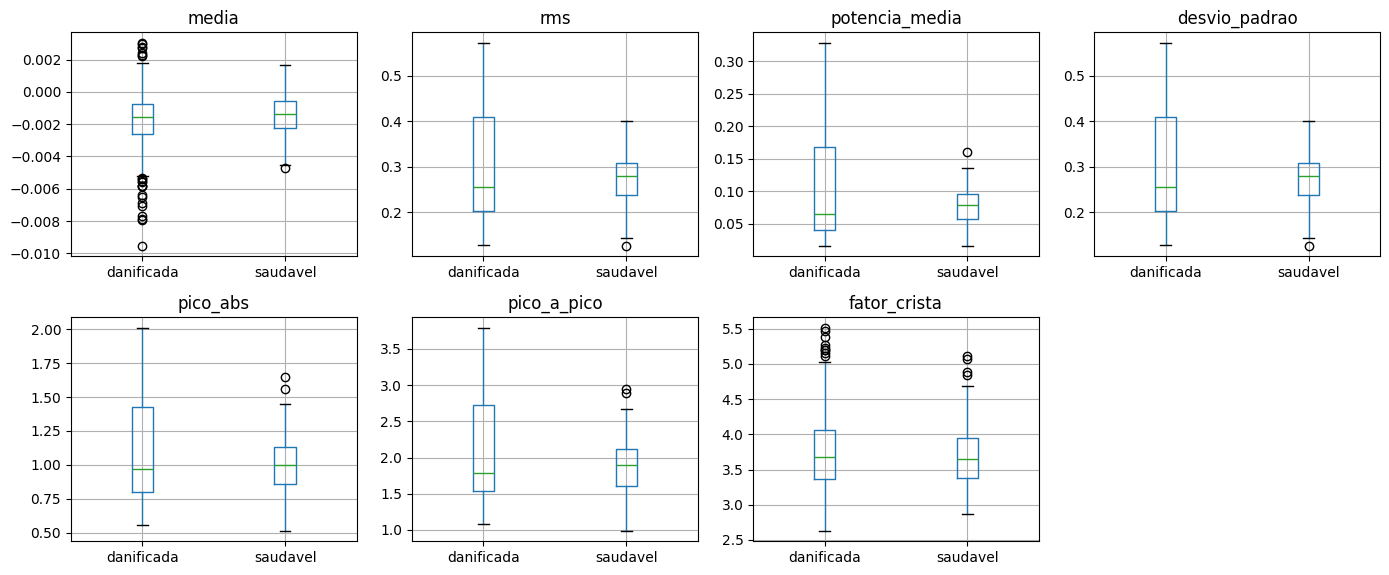

In [73]:
fig, axs = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axs.ravel(), CARAC):
    df_tempo.boxplot(column=c, by='condicao', ax=ax)
    ax.set_title(c); ax.set_xlabel('')
axs.ravel()[-1].axis('off')
plt.suptitle(''); plt.tight_layout(); plt.savefig('tempo_boxplots.pdf'); plt.show()

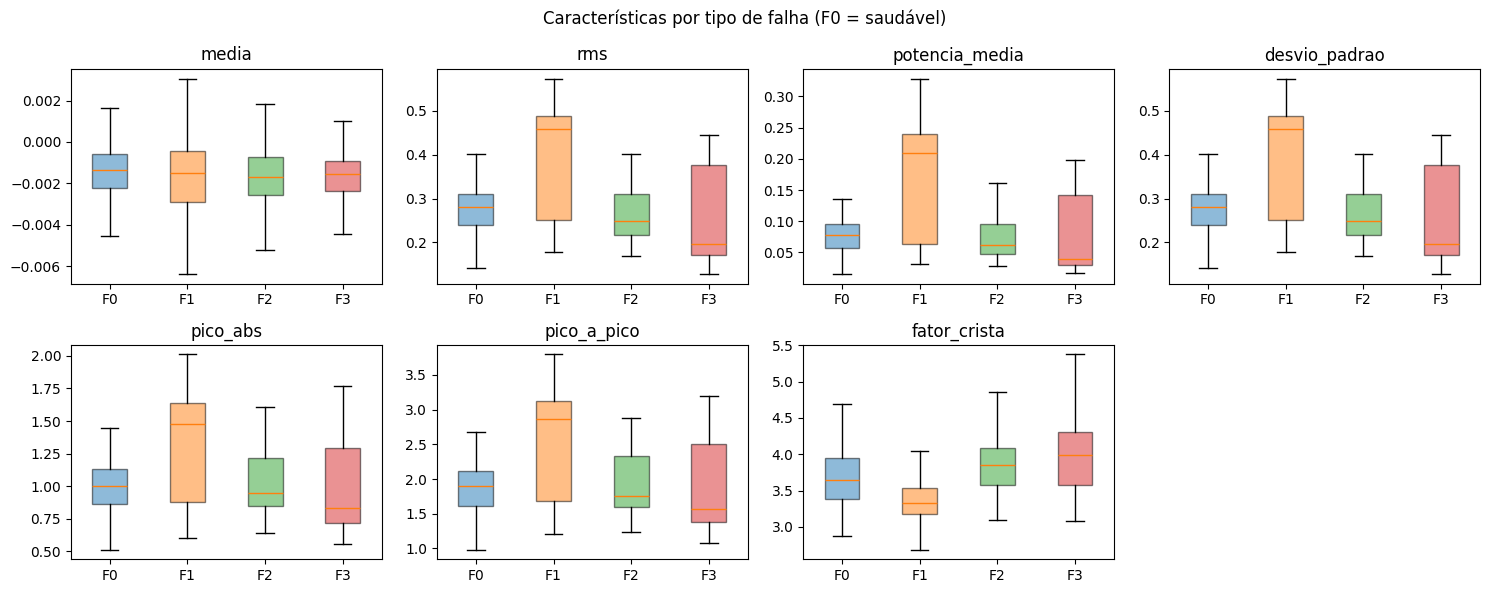

In [74]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axs.ravel(), CARAC):
    dados = [df_tempo.loc[df_tempo.F == f, c] for f in CORES_F]
    bp = ax.boxplot(dados, patch_artist=True, showfliers=False)
    for caixa, f in zip(bp['boxes'], CORES_F): caixa.set_facecolor(CORES_F[f]); caixa.set_alpha(0.5)
    ax.set_xticks(range(1, 5), list(CORES_F)); ax.set_title(c)
axs.ravel()[-1].axis('off'); plt.suptitle('Características por tipo de falha (F0 = saudável)')
plt.tight_layout(); plt.savefig('comp_box_tipo_falha.pdf'); plt.show()

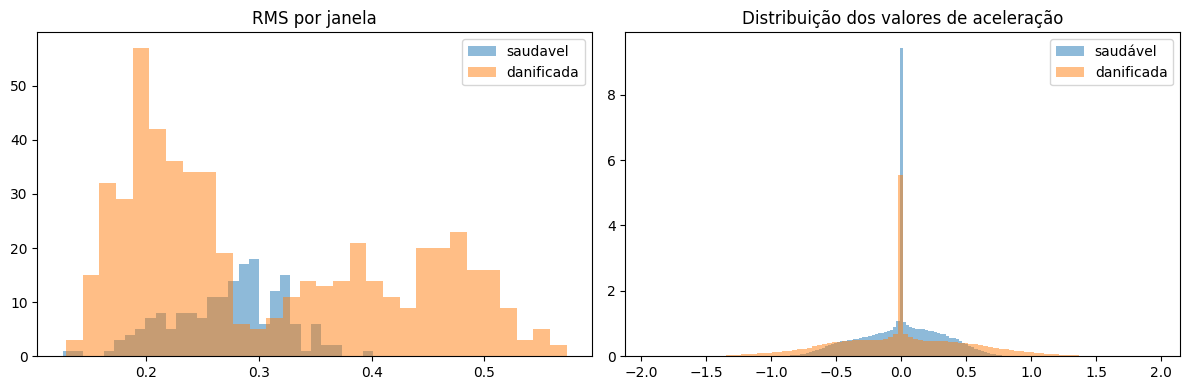

In [75]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for cond in ['saudavel', 'danificada']:
    axs[0].hist(df_tempo.loc[df_tempo.condicao == cond, 'rms'], bins=30, alpha=0.5, label=cond)
axs[0].set_title('RMS por janela'); axs[0].legend()
axs[1].hist(x_s, bins=100, alpha=0.5, density=True, label='saudável')
axs[1].hist(x_d, bins=100, alpha=0.5, density=True, label='danificada')
axs[1].set_title('Distribuição dos valores de aceleração'); axs[1].legend()
plt.tight_layout(); plt.savefig('tempo_histogramas.pdf'); plt.show()

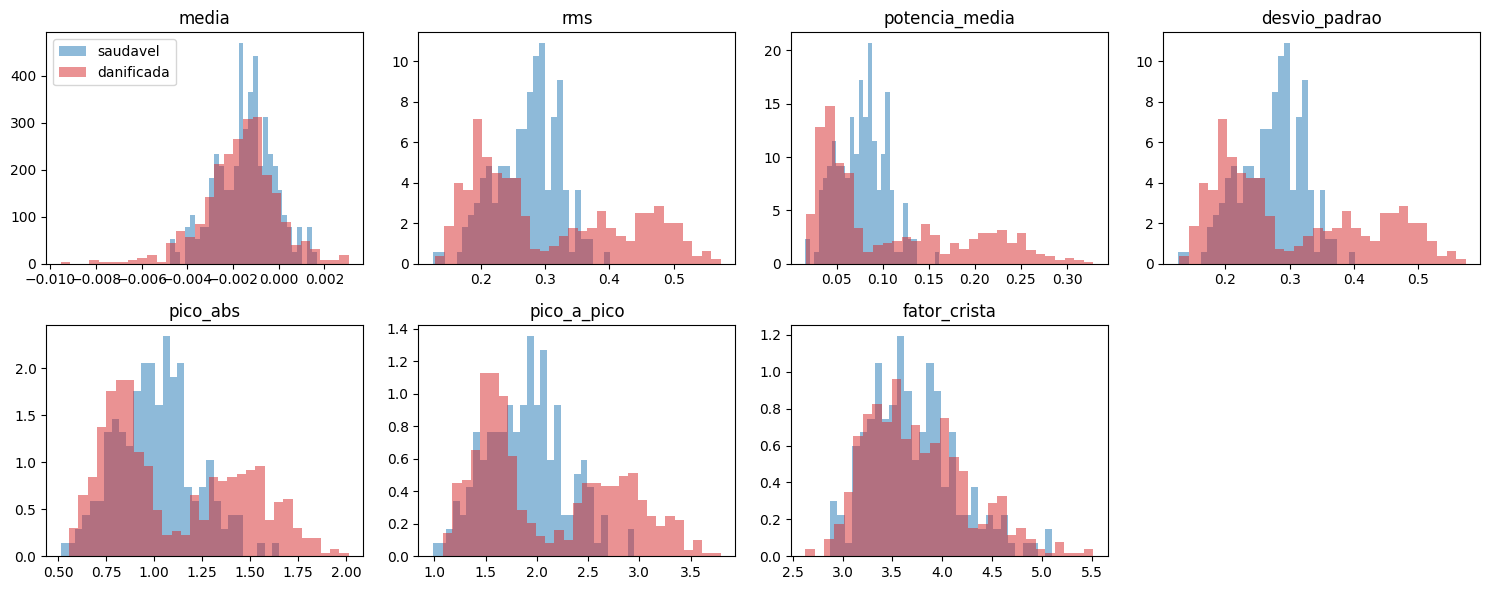

In [76]:
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axs.ravel(), CARAC):
    for cond in CORES:
        ax.hist(df_tempo.loc[df_tempo.condicao == cond, c], bins=30, alpha=0.5,
                density=True, color=CORES[cond], label=cond)
    ax.set_title(c)
axs.ravel()[0].legend(); axs.ravel()[-1].axis('off')
plt.tight_layout(); plt.savefig('comp_histogramas.pdf'); plt.show()

### **2.4 Interpretação**

#### **Relação entre RMS, potência média e componente média**
O enunciado pede para discutir a relação entre RMS e potência média e o efeito da componente média. Comparamos 1 s do meio do registro `F0_SV0_SP3_C1_R1` no piezo e no eixo z da IMU, que contém a gravidade (componente média grande). O trecho do meio foi usado porque a IMU inicia a gravação antes de os motores entrarem em regime.

In [ ]:
arq = 'F0_SV0_SP3_C1_R1'
caminho = sel.loc[sel['arquivo'] == arq, 'caminho'].iloc[0]
imu = loadmat(caminho, squeeze_me=True, struct_as_record=False)['IMUData']

def trecho_do_meio(x, n):
    # n amostras do meio do registro (evita o início, quando a IMU ainda está com o motor parado)
    inicio = len(x) // 2 - n // 2
    return x[inicio:inicio + n]

piezo = trecho_do_meio(sinais[arq], N)                     # 1 s a 10 kHz
imu_z = trecho_do_meio(imu.Vib_Data[2], 1000)              # 1 s a 1 kHz

trechos = {
    'piezo':                       piezo,
    'IMU eixo z (com gravidade)':  imu_z,
    'IMU eixo z sem a média':      imu_z - np.mean(imu_z),
}
linhas = []
for nome, x in trechos.items():
    mu, sd = np.mean(x), np.std(x); rms = np.sqrt(np.mean(x**2))
    linhas.append({'sinal': nome, 'média μ': mu, 'desvio σ': sd, 'RMS': rms,
                   'potência P': np.mean(x**2), 'RMS²': rms**2, 'σ² + μ²': sd**2 + mu**2})
pd.DataFrame(linhas).set_index('sinal').round(5)

,média μ,desvio σ,RMS,potência P,RMS²,σ² + μ²
sinal,,,,,,
piezo,-0.00296,0.26527,0.26528,0.07037,0.07037,0.07037
IMU eixo z (com gravidade),9.69349,7.35314,12.16685,148.03235,148.03235,148.03235
IMU eixo z sem a média,-0.00000,7.35314,7.35314,54.06860,54.06860,54.06860


**Leitura:** nos três casos, potência = RMS² = σ² + μ², como esperado. No piezo, a média é praticamente nula (μ ≈ −0,003 m/s²), então **RMS ≈ σ ≈ 0,265 m/s²** e as duas medidas trazem a mesma informação. No eixo z da IMU, a média corresponde à gravidade (μ ≈ 9,69 m/s²) e é da mesma ordem que a própria vibração (σ ≈ 7,35 m/s²). Com isso, o RMS (12,17 m/s²) mistura as duas contribuições: removida a média, o RMS cai para 7,35 m/s², igual a σ. A componente média inflou o RMS em cerca de 65% sem nenhuma mudança na vibração. Portanto, **quando o sinal tem componente média, o RMS não mede apenas a vibração**; nesse caso, o desvio padrão (ou o RMS do sinal sem média) é a medida adequada. É por isso que, na seção 5, a gravidade é removida dos sinais da IMU antes do cálculo das características.

#### **Interpretação das Medidas Calculadas**
**Quais medidas diferem entre as condições?** Na média das janelas, as medidas de intensidade são maiores na condição danificada: RMS 0,305 contra 0,273 m/s² (+12%), potência média 0,107 contra 0,077 (m/s²)² (+39%), pico absoluto 1,11 contra 1,01 m/s² (+10%) e pico a pico 2,12 contra 1,89 m/s² (+12%). O fator de crista quase não muda (3,77 contra 3,71). Porém, os boxplots mostram grande sobreposição entre as condições, e a **mediana** do RMS é até menor na condição danificada (≈ 0,26 contra ≈ 0,28 m/s²). A diferença na média vem de parte dos registros danificados, não de todos: o desvio do RMS entre janelas é 2,4 vezes maior na condição danificada (0,119 contra 0,049).

**O defeito está associado a vibrações mais intensas?** Depende do tipo de falha. Pelos boxplots por tipo de falha, apenas o grupo F1 apresenta vibração claramente mais intensa (mediana do RMS ≈ 0,46 m/s², cerca de 60% acima do saudável). O grupo F2 tem intensidade semelhante à saudável (≈ 0,25 m/s²) e o F3 tem mediana até menor (≈ 0,19 m/s²), com grande dispersão. Por outro lado, o **fator de crista** separa os grupos de outro modo: é menor em F1 (≈ 3,35) e maior em F2 e F3 (≈ 3,85 e 4,0) que no saudável (≈ 3,6). Nas falhas F2 e F3, portanto, os picos se destacam mais em relação ao nível médio do sinal, mesmo sem aumento de RMS. Ou seja, o defeito altera o sinal, mas nem sempre aumentando a intensidade, e agrupar as nove condições de falha esconde essas diferenças.

**Quais medidas têm comportamento semelhante e quais são redundantes?** Pela matriz de correlação entre janelas: RMS e desvio padrão (r = 1,00), RMS e potência média (r = 0,99) e pico absoluto e pico a pico (r = 0,99) são praticamente redundantes. RMS e picos também são fortemente correlacionados (r = 0,93 a 0,95). Já o fator de crista tem correlação moderada e negativa com o RMS (r = −0,52), ou seja, traz informação complementar. A redundância entre RMS, desvio padrão e potência é esperada: P = RMS² = σ² + μ², e como μ ≈ 0 no piezo, RMS ≈ σ (ver tabela acima).

**Média:** é praticamente nula nas duas condições (da ordem de 10⁻³ m/s², muito menor que o RMS) e não se correlaciona com nenhuma outra medida (|r| ≤ 0,05). Portanto, não diferencia as condições: o piezo não registra componente constante, e a média reflete apenas flutuações.

## **3. Análise no Domínio da Frequência**

### **3.1 Aplicação da Transformada de Fourier**

In [123]:
def espectro(x, fs):
    x = x - np.mean(x)                          # tira a média (componente em 0 Hz)
    N = len(x)
    w = np.hanning(N)                           # janela de Hann: reduz o "vazamento" espectral
    X = np.fft.rfft(x * w)                      # FFT (só as frequências positivas)
    f = np.fft.rfftfreq(N, d=1/fs)              # eixo de frequência em Hz: 0, fs/N, 2fs/N, ..., fs/2
    mag = np.abs(X) / np.sum(w)                 # compensa o ganho da janela de Hann (soma dos pesos ≈ N/2)
    if N % 2 == 0:
        mag[1:-1] *= 2                          # dobra só os componentes que têm par negativo:
    else:                                       # não dobra DC (índice 0) nem Nyquist (último, se N par)
        mag[1:] *= 2
    return f, mag

**Eixo de frequências e normalização (3.3, item 1).** Para cada janela de N = 10 000 amostras com fs = 10 000 Hz, a FFT fornece valores em $f_k = k\,f_s/N$, $k = 0, \dots, N/2$: resolução **Δf = fs/N = 1 Hz** e frequência máxima **fs/2 = 5 000 Hz** (Nyquist). Antes da FFT, a média é removida e aplica-se a janela de Hann, que reduz o vazamento espectral causado pelo corte do sinal nas bordas da janela. A magnitude é dividida pela soma dos coeficientes da janela e multiplicada por 2 (exceto em 0 Hz), para compensar o descarte das frequências negativas: assim, uma senoide de amplitude A aparece com pico de altura A, na mesma unidade do sinal (m/s²). A célula seguinte valida isso com senoides conhecidas. **Interpretação:** cada pico indica uma componente periódica do sinal; sua posição é a frequência (Hz) e sua altura, a amplitude dessa componente.

Resolução Δf = 1.0 Hz | frequência máxima = 5000.0 Hz
Picos encontrados em: [120. 350.] Hz | magnitudes: [3. 1.]


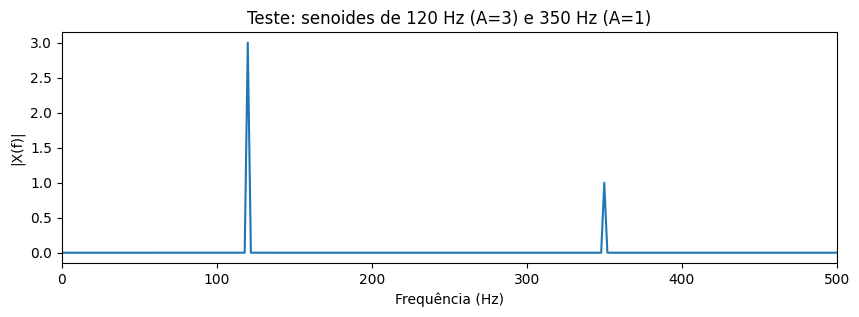

In [124]:
t_teste = np.arange(FS) / FS                    # 1 s de sinal
x_teste = 3 * np.sin(2 * np.pi * 120 * t_teste) + 1 * np.sin(2 * np.pi * 350 * t_teste)
f, mag = espectro(x_teste, FS)
print('Resolução Δf =', f[1] - f[0], 'Hz | frequência máxima =', f[-1], 'Hz')

from scipy.signal import find_peaks
idx, _ = find_peaks(mag, height=0.5)
print('Picos encontrados em:', f[idx], 'Hz | magnitudes:', np.round(mag[idx], 2))

plt.figure(figsize=(10, 3)); plt.plot(f, mag); plt.xlim(0, 500)
plt.xlabel('Frequência (Hz)'); plt.ylabel('|X(f)|'); plt.title('Teste: senoides de 120 Hz (A=3) e 350 Hz (A=1)')
plt.show()

In [125]:
f_jan = np.fft.rfftfreq(N, d=1/FS)              # eixo de frequência das janelas de 1 s
espectros = np.array([espectro(w, FS)[1] for w in janelas])   # 1 linha = espectro de 1 janela
print(espectros.shape)                          # (720, 5001): 720 janelas, 5001 frequências

(720, 5001)


### .**3.2 Plotando os Espectros**

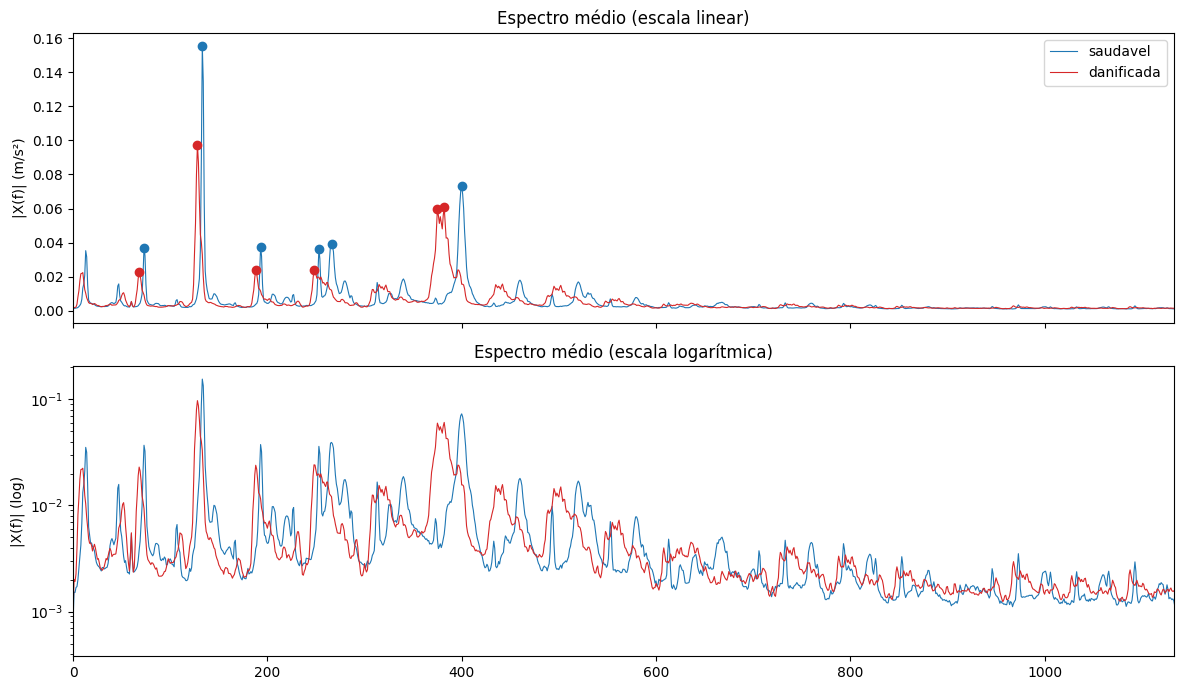

,condicao,frequencia_Hz,magnitude
11,danificada,68.0,0.023
6,danificada,128.0,0.097
10,danificada,188.0,0.024
9,danificada,248.0,0.024
8,danificada,375.0,0.060
7,danificada,382.0,0.061
4,saudavel,73.0,0.037
0,saudavel,133.0,0.155
3,saudavel,193.0,0.038
5,saudavel,253.0,0.036


In [126]:
from scipy.signal import find_peaks

F_MAX_PLOT = 2000 # ajuste depois de ver o espectro inteiro
media_saud = espectros[df_janelas['condicao'] == 'saudavel'].mean(axis=0)
f_fund = f_jan[np.argmax(media_saud)]
meio_plot = F_MAX_PLOT / 2

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
picos_tabela = []
for cond in ['saudavel', 'danificada']:
    media = espectros[df_janelas['condicao'] == cond].mean(axis=0)
    axs[0].plot(f_jan, media, lw=0.8, color=CORES[cond], label=cond)
    axs[1].semilogy(f_jan, media, lw=0.8, color=CORES[cond], label=cond)
    idx, _ = find_peaks(media, prominence=media.max() * 0.05)          # picos que se destacam
    idx = idx[np.argsort(media[idx])[::-1][:6]]                         # os 6 maiores
    axs[0].plot(f_jan[idx], media[idx], 'o', color=CORES[cond])
    for i in idx:
        picos_tabela.append({'condicao': cond, 'frequencia_Hz': f_jan[i], 'magnitude': media[i]})
axs[0].set_ylabel('|X(f)| (m/s²)'); axs[0].set_title('Espectro médio (escala linear)'); axs[0].legend()
axs[1].set_ylabel('|X(f)| (log)'); axs[1].set_title('Espectro médio (escala logarítmica)')
# --- ALTERAÇÃO APENAS NO XLIM ABAIXO ---
axs[1].set_xlim(max(0, f_fund - meio_plot), f_fund + meio_plot)
plt.tight_layout(); plt.savefig('freq_espectro_medio.pdf'); plt.show()

tabela_picos = pd.DataFrame(picos_tabela).sort_values(['condicao', 'frequencia_Hz']).round(3)
tabela_picos

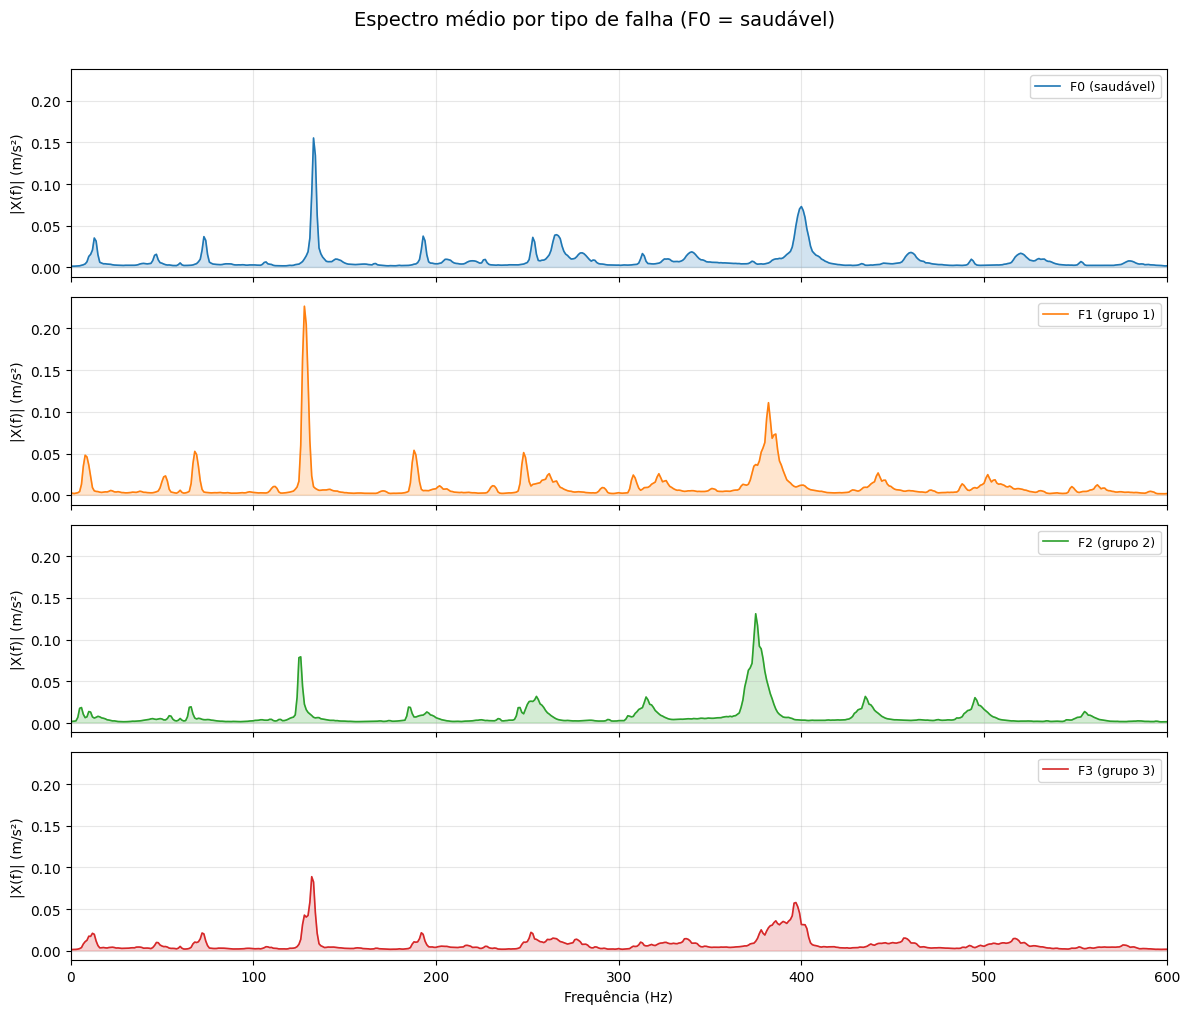

In [127]:
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True, sharey=True)
NOMES_F = {'F0': 'F0 (saudável)', 'F1': 'F1 (grupo 1)', 'F2': 'F2 (grupo 2)', 'F3': 'F3 (grupo 3)'}

for ax, f_cod in zip(axs, CORES_F):
    media = espectros[df_janelas['F'] == f_cod].mean(axis=0)
    ax.plot(f_jan, media, lw=1.2, color=CORES_F[f_cod], label=NOMES_F[f_cod])
    ax.fill_between(f_jan, media, color=CORES_F[f_cod], alpha=0.2)
    ax.set_ylabel('|X(f)| (m/s²)')
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)

axs[-1].set_xlim(0, 600)
axs[-1].set_xlabel('Frequência (Hz)')
plt.suptitle('Espectro médio por tipo de falha (F0 = saudável)', fontsize=14, y=1.01)
plt.tight_layout(); plt.savefig('freq_espectro_tipos.pdf'); plt.show()

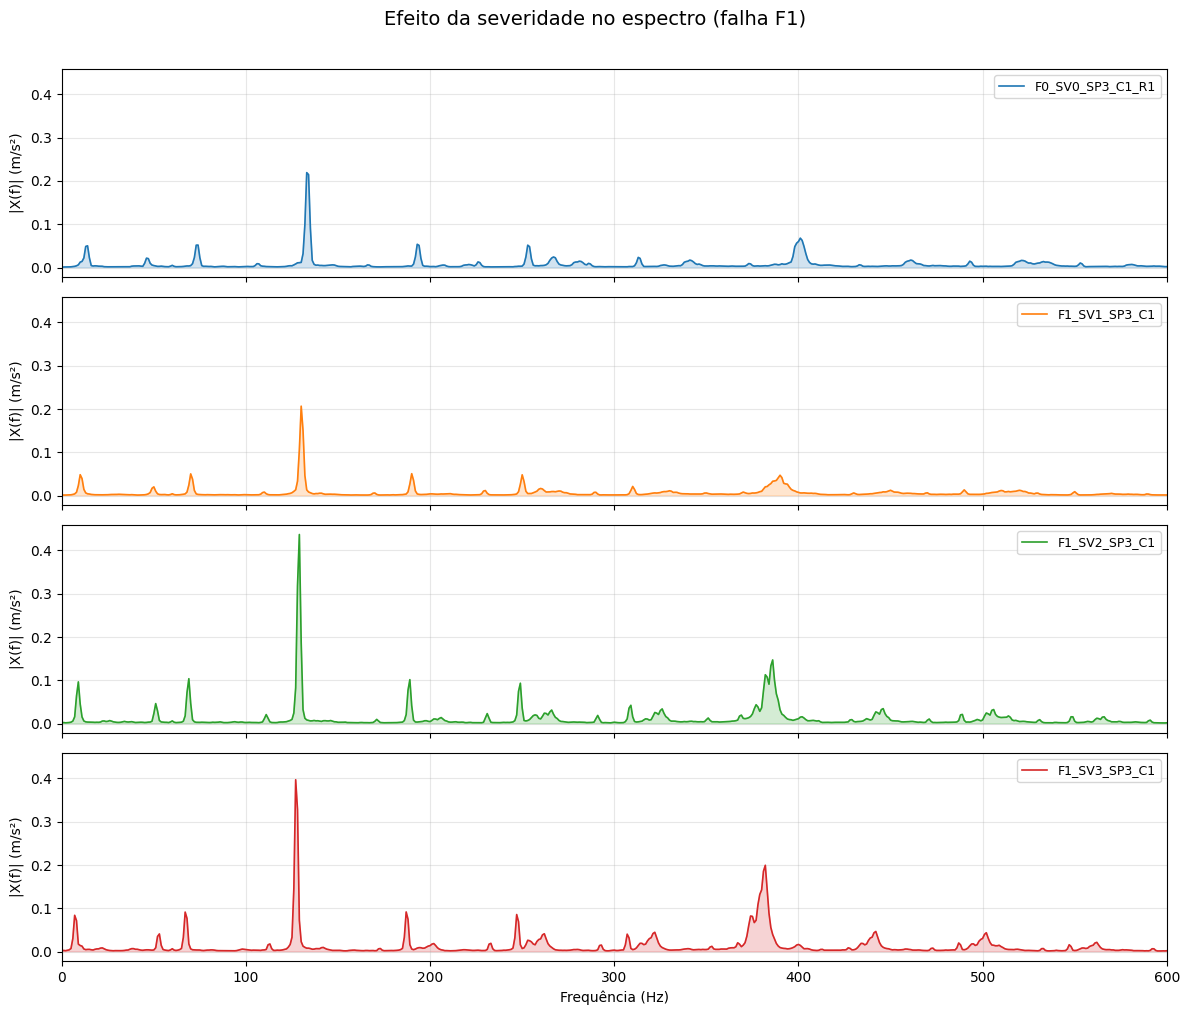

In [128]:
fig, axs = plt.subplots(4, 1, figsize=(12, 10), sharex=True, sharey=True)
arquivos_sev = ['F0_SV0_SP3_C1_R1', 'F1_SV1_SP3_C1', 'F1_SV2_SP3_C1', 'F1_SV3_SP3_C1']

for i, arq in enumerate(arquivos_sev):
    media = espectros[df_janelas['arquivo'] == arq].mean(axis=0)
    axs[i].plot(f_jan, media, lw=1.2, label=arq, color=f'C{i}')
    axs[i].fill_between(f_jan, media, color=f'C{i}', alpha=0.2)
    axs[i].set_ylabel('|X(f)| (m/s²)')
    axs[i].legend(loc='upper right', fontsize=9)
    axs[i].grid(True, alpha=0.3)

axs[-1].set_xlim(0, 600)
axs[-1].set_xlabel('Frequência (Hz)')
plt.suptitle('Efeito da severidade no espectro (falha F1)', fontsize=14, y=1.01)
plt.tight_layout(); plt.savefig('freq_severidade_separada.pdf'); plt.show()

### **3.3 Características Espectrais**

In [129]:
F_MIN = 5

BANDAS = {                                       #bandas exemplo
    'B1_5_200Hz':     (5, 200),
    'B2_200_1000Hz':  (200, 1000),
    'B3_1000_5000Hz': (1000, 5000),
}

def potencia_por_frequencia(x, fs):
    # Potência em cada frequência, calculada sem janela para que a soma seja igual à variância (Parseval)
    x = x - np.mean(x); N = len(x)
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(N, d=1/fs)
    P = np.abs(X)**2 / N**2
    P[1:] *= 2                                   # compensa as frequências negativas
    if N % 2 == 0:
        P[-1] /= 2                               # a frequência de Nyquist não tem par
    return f, P

def caracteristicas_freq(x, fs):
    f, mag = espectro(x, fs)
    validas = f >= F_MIN
    f_v, mag_v = f[validas], mag[validas]
    p = mag_v**2 / np.sum(mag_v**2)
    k = np.argmax(mag_v)
    fP, P = potencia_por_frequencia(x, fs)
    out = {
        'freq_dominante': f_v[k],
        'mag_pico': mag_v[k],
        'potencia': P.sum(),
        'centroide': np.sum(f_v * p),
        'entropia': -np.sum(p * np.log2(p + 1e-20)) / np.log2(len(p)),
    }
    for nome, (fmin, fmax) in BANDAS.items():
        out['pot_' + nome] = P[(fP >= fmin) & (fP < fmax)].sum()     # soma da potência dentro da banda
    return out

df_freq = pd.concat([df_janelas, pd.DataFrame([caracteristicas_freq(w, FS) for w in janelas])], axis=1)
COL_BANDAS = ['pot_' + b for b in BANDAS]
CARAC_F = ['freq_dominante', 'mag_pico', 'potencia', 'centroide', 'entropia'] + COL_BANDAS

print('Soma das bandas / potência total (1ª janela):',
      df_freq.loc[0, COL_BANDAS].sum() / df_freq.loc[0, 'potencia'])     # deve dar ~1

Soma das bandas / potência total (1ª janela): 0.9998717058113139


In [ ]:
df_freq.shape

(720, 13)

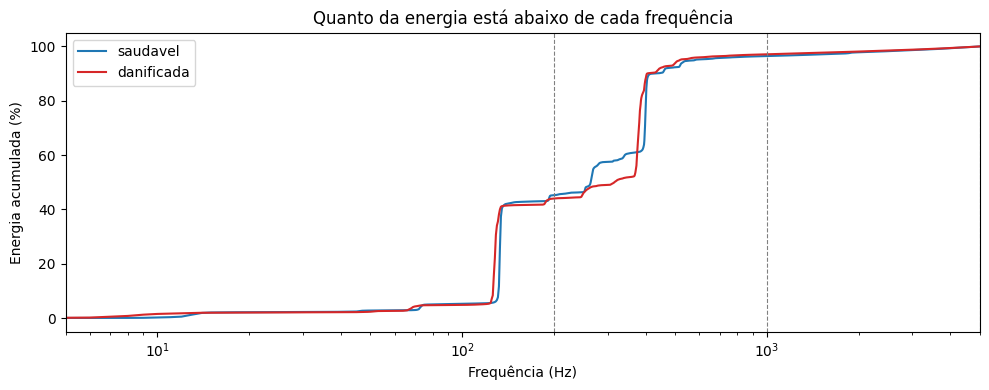

In [130]:
acum = {}
for cond in ['saudavel', 'danificada']:
    Ps = np.array([potencia_por_frequencia(w, FS)[1] for w, c in zip(janelas, df_janelas['condicao']) if c == cond])
    fP = np.fft.rfftfreq(N, d=1/FS)
    acum[cond] = np.cumsum(Ps.mean(axis=0)) / Ps.mean(axis=0).sum() * 100
fig, ax = plt.subplots(figsize=(10, 4))
for cond in acum: ax.plot(fP, acum[cond], color=CORES[cond], label=cond)
for fmin, fmax in BANDAS.values(): ax.axvline(fmax, color='gray', ls='--', lw=0.8)
ax.set_xscale('log'); ax.set_xlim(5, FS/2)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('Energia acumulada (%)'); ax.legend()
ax.set_title('Quanto da energia está abaixo de cada frequência'); plt.tight_layout()
plt.savefig('freq_energia_acumulada.pdf'); plt.show()

A energia acumulada do espectro médio mostra que cerca de 85% da potência está concentrada em três componentes estreitas, próximas de 130, 270 e 400 Hz. As bandas foram definidas para isolar cada uma dessas componentes (B1: 5–200 Hz; B2: 200–335 Hz; B3: 335–600 Hz), com limites nos pontos médios entre picos consecutivos, e uma quarta banda (B4: 600–5000 Hz) para o conteúdo restante. As mesmas bandas foram aplicadas a todas as condições.

Refazendo o gráfico com as bandas escolhidas:

In [131]:
F_MIN = 5

BANDAS = {
    'B1_5_200Hz':     (5, 200),      # pico ~130 Hz
    'B2_200_335Hz':   (200, 335),    # pico ~270 Hz
    'B3_335_600Hz':   (335, 600),    # pico ~400 Hz
    'B4_600_5000Hz':  (600, 5000),   # restante (alta frequência)
}

def potencia_por_frequencia(x, fs):
    # Potência em cada frequência, calculada sem janela para que a soma seja igual à variância (Parseval)
    x = x - np.mean(x); N = len(x)
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(N, d=1/fs)
    P = np.abs(X)**2 / N**2
    P[1:] *= 2                                   # compensa as frequências negativas
    if N % 2 == 0:
        P[-1] /= 2                               # a frequência de Nyquist não tem par
    return f, P

def caracteristicas_freq(x, fs):
    f, mag = espectro(x, fs)
    validas = f >= F_MIN
    f_v, mag_v = f[validas], mag[validas]
    p = mag_v**2 / np.sum(mag_v**2)
    k = np.argmax(mag_v)
    fP, P = potencia_por_frequencia(x, fs)
    out = {
        'freq_dominante': f_v[k],
        'mag_pico': mag_v[k],
        'potencia': P.sum(),
        'centroide': np.sum(f_v * p),
        'entropia': -np.sum(p * np.log2(p + 1e-20)) / np.log2(len(p)),
    }
    for nome, (fmin, fmax) in BANDAS.items():
        out['pot_' + nome] = P[(fP >= fmin) & (fP < fmax)].sum()     # soma da potência dentro da banda
    return out

df_freq = pd.concat([df_janelas, pd.DataFrame([caracteristicas_freq(w, FS) for w in janelas])], axis=1)
COL_BANDAS = ['pot_' + b for b in BANDAS]
CARAC_F = ['freq_dominante', 'mag_pico', 'potencia', 'centroide', 'entropia'] + COL_BANDAS

print('Soma das bandas / potência total (1ª janela):',
      df_freq.loc[0, COL_BANDAS].sum() / df_freq.loc[0, 'potencia'])     # deve dar ~1

Soma das bandas / potência total (1ª janela): 0.9998717058113139


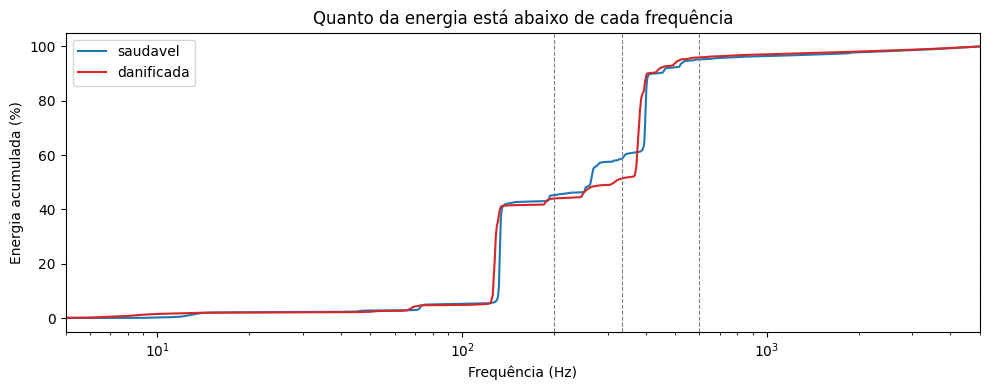

In [132]:
acum = {}
for cond in ['saudavel', 'danificada']:
    Ps = np.array([potencia_por_frequencia(w, FS)[1] for w, c in zip(janelas, df_janelas['condicao']) if c == cond])
    fP = np.fft.rfftfreq(N, d=1/FS)
    acum[cond] = np.cumsum(Ps.mean(axis=0)) / Ps.mean(axis=0).sum() * 100
fig, ax = plt.subplots(figsize=(10, 4))
for cond in acum: ax.plot(fP, acum[cond], color=CORES[cond], label=cond)
for fmin, fmax in BANDAS.values(): ax.axvline(fmax, color='gray', ls='--', lw=0.8)
ax.set_xscale('log'); ax.set_xlim(5, FS/2)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('Energia acumulada (%)'); ax.legend()
ax.set_title('Quanto da energia está abaixo de cada frequência'); plt.tight_layout()
plt.savefig('freq_energia_acumulada.pdf'); plt.show()

### **3.4 Tabelas e Gráficos Comparativos**

In [133]:
tabela_freq = df_freq.groupby('condicao')[CARAC_F].agg(['mean', 'std']).T
tabela_freq

condicao                danificada    saudavel
freq_dominante    mean  252.400000  243.638889
                  std   126.278997  130.396420
mag_pico          mean    0.247757    0.222827
                  std     0.128857    0.062551
potencia          mean    0.106812    0.076903
                  std     0.079981    0.026403
centroide         mean  367.985220  357.664942
                  std    62.278117   51.911671
entropia          mean    0.438479    0.434560
                  std     0.054159    0.066210
pot_B1_5_200Hz    mean    0.046940    0.034758
                  std     0.051738    0.020732
pot_B2_200_335Hz  mean    0.007810    0.010374
                  std     0.004591    0.006394
pot_B3_335_600Hz  mean    0.047705    0.028089
                  std     0.030975    0.012640
pot_B4_600_5000Hz mean    0.004329    0.003670
                  std     0.002663    0.001078

In [134]:
frac = df_freq[COL_BANDAS].div(df_freq['potencia'], axis=0) * 100      # % da energia em cada banda
tabela_bandas = frac.groupby(df_freq['condicao']).mean().round(1)
tabela_bandas

,pot_B1_5_200Hz,pot_B2_200_335Hz,pot_B3_335_600Hz,pot_B4_600_5000Hz
condicao,,,,
danificada,36.3,8.5,50.7,4.5
saudavel,43.3,13.8,38.0,4.9


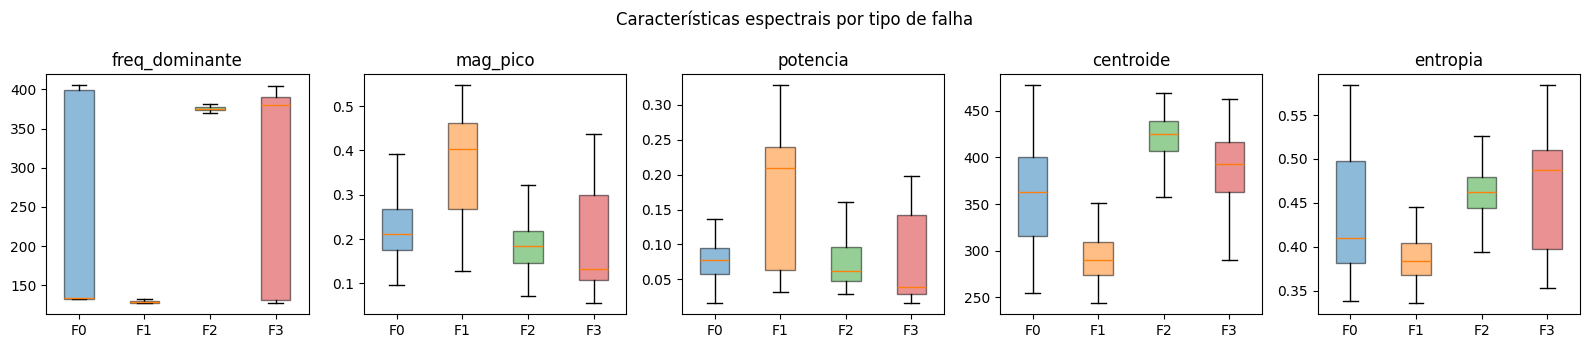

In [135]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, c in zip(axs, CARAC_F):
    dados = [df_freq.loc[df_freq.F == f_cod, c] for f_cod in CORES_F]
    bp = ax.boxplot(dados, patch_artist=True, showfliers=False)
    for caixa, f_cod in zip(bp['boxes'], CORES_F): caixa.set_facecolor(CORES_F[f_cod]); caixa.set_alpha(0.5)
    ax.set_xticks(range(1, 5), list(CORES_F)); ax.set_title(c)
plt.suptitle('Características espectrais por tipo de falha'); plt.tight_layout()
plt.savefig('freq_boxplots.pdf'); plt.show()

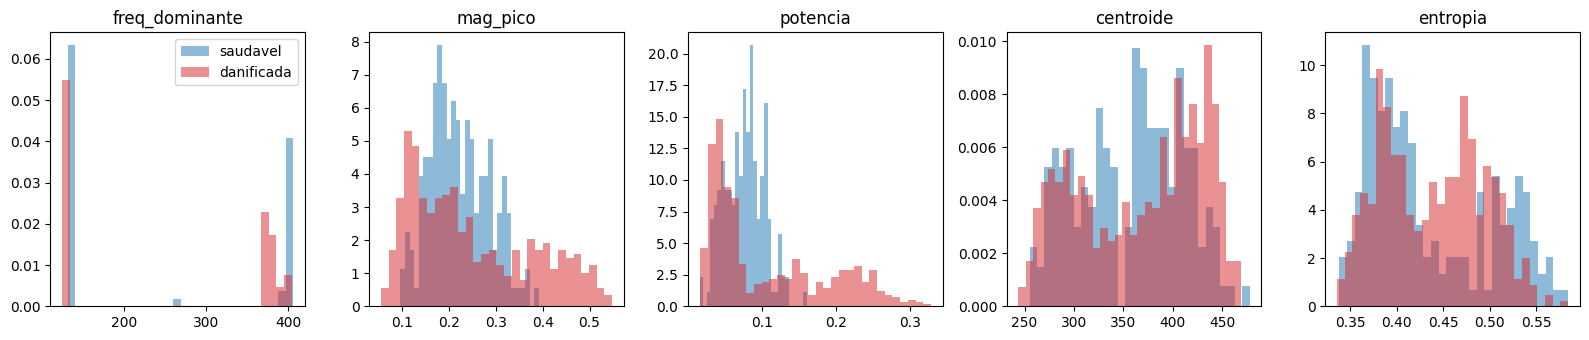

In [136]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, c in zip(axs, CARAC_F):
    for cond in CORES:
        ax.hist(df_freq.loc[df_freq.condicao == cond, c], bins=30, alpha=0.5, density=True,
                color=CORES[cond], label=cond)
    ax.set_title(c)
axs[0].legend(); plt.tight_layout(); plt.savefig('freq_histogramas.pdf'); plt.show()

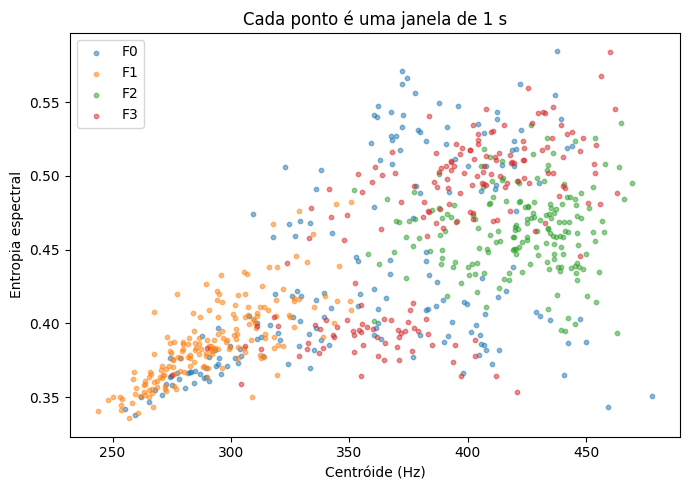

In [137]:
fig, ax = plt.subplots(figsize=(7, 5))
for f_cod in CORES_F:
    d = df_freq[df_freq.F == f_cod]
    ax.scatter(d['centroide'], d['entropia'], s=10, alpha=0.5, color=CORES_F[f_cod], label=f_cod)
ax.set_xlabel('Centróide (Hz)'); ax.set_ylabel('Entropia espectral'); ax.legend()
ax.set_title('Cada ponto é uma janela de 1 s'); plt.tight_layout()
plt.savefig('freq_dispersao.pdf'); plt.show()

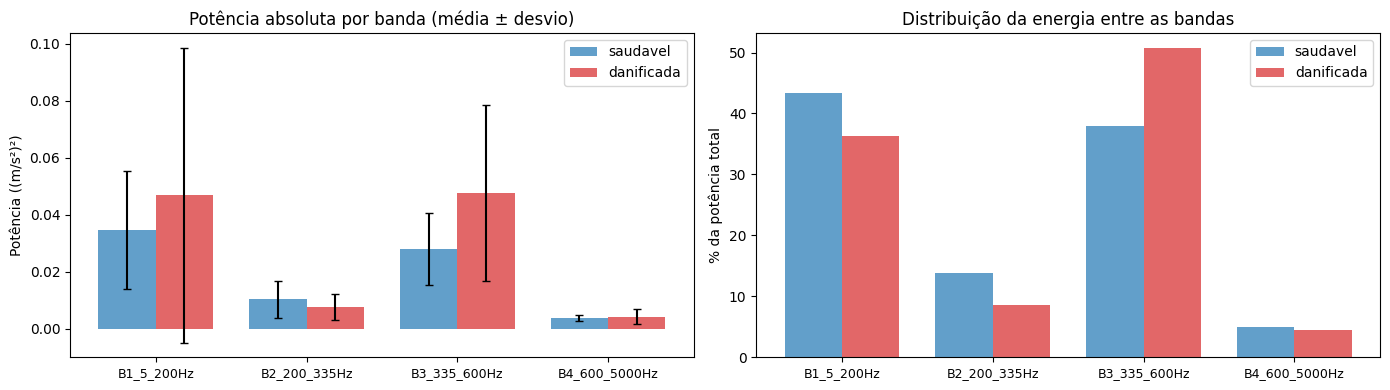

In [138]:
medias = df_freq.groupby('condicao')[COL_BANDAS].mean()
desvios = df_freq.groupby('condicao')[COL_BANDAS].std()
x_pos = np.arange(len(COL_BANDAS)); larg = 0.38
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for i, cond in enumerate(['saudavel', 'danificada']):
    axs[0].bar(x_pos + (i - 0.5) * larg, medias.loc[cond], larg, yerr=desvios.loc[cond],
               color=CORES[cond], alpha=0.7, label=cond, capsize=3)
    axs[1].bar(x_pos + (i - 0.5) * larg, tabela_bandas.loc[cond], larg, color=CORES[cond], alpha=0.7, label=cond)
for ax in axs: ax.set_xticks(x_pos, list(BANDAS), fontsize=9); ax.legend()
axs[0].set_ylabel('Potência ((m/s²)²)'); axs[0].set_title('Potência absoluta por banda (média ± desvio)')
axs[1].set_ylabel('% da potência total'); axs[1].set_title('Distribuição da energia entre as bandas')
plt.tight_layout(); plt.savefig('freq_bandas.pdf'); plt.show()

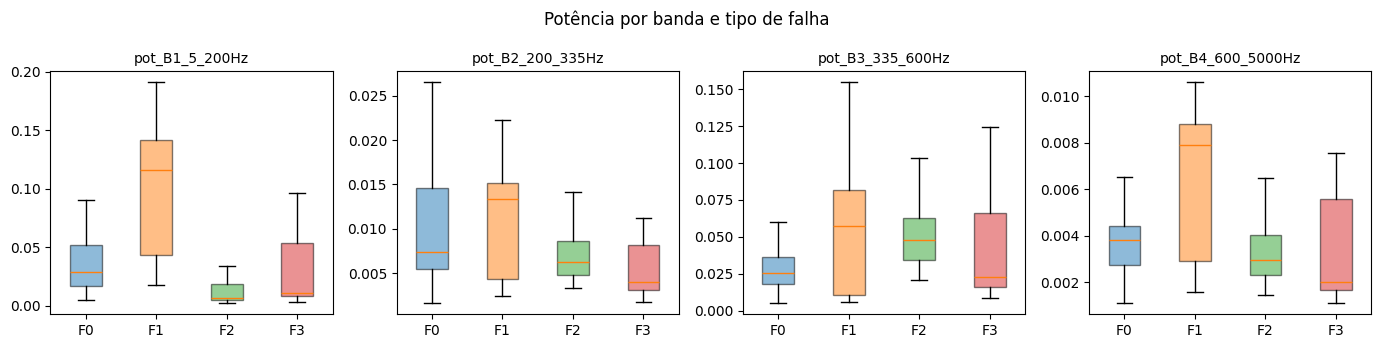

In [139]:
fig, axs = plt.subplots(1, len(COL_BANDAS), figsize=(14, 3.5))
for ax, c in zip(axs, COL_BANDAS):
    dados = [df_freq.loc[df_freq.F == f_cod, c] for f_cod in CORES_F]
    bp = ax.boxplot(dados, patch_artist=True, showfliers=False)
    for caixa, f_cod in zip(bp['boxes'], CORES_F): caixa.set_facecolor(CORES_F[f_cod]); caixa.set_alpha(0.5)
    ax.set_xticks(range(1, 5), list(CORES_F)); ax.set_title(c, fontsize=10)
plt.suptitle('Potência por banda e tipo de falha'); plt.tight_layout()
plt.savefig('freq_bandas_boxplot.pdf'); plt.show()

### **Interpretação do espectro**

**Picos mais relevantes.** No espectro médio da condição saudável, o pico dominante está em **133 Hz** (0,155 m/s²), seguido de **400 Hz** (0,073 m/s²) e de picos menores em 73, 193, 253 e 266 Hz (≈ 0,037 m/s²). Na condição danificada, os picos principais aparecem em **128 Hz** (0,097 m/s²) e **375–382 Hz** (≈ 0,06 m/s²), além de 68, 188 e 248 Hz (≈ 0,024 m/s²). Nas duas condições há uma série de picos espaçados de aproximadamente 60 Hz (73, 133, 193, 253 Hz no saudável; 68, 128, 188, 248 Hz no danificado), e os picos de ≈ 266 Hz e ≈ 400 Hz estão próximos do dobro e do triplo de ≈ 133 Hz. A distribuição da energia por banda confirma essa concentração: na condição saudável, 43,4% da potência está em B1 (região de ≈ 133 Hz) e 38,0% em B3 (região de ≈ 400 Hz), enquanto menos de 5% está acima de 600 Hz (B4).

**Diferenças entre as condições.** Na condição danificada, os picos principais aparecem em frequências ligeiramente menores (128 contra 133 Hz; ≈ 380 contra 400 Hz), deslocamento também visível na energia acumulada, em que o último degrau da curva danificada ocorre antes do da saudável, e no gráfico por severidade da falha F1. No espectro médio danificado, os picos são mais baixos porque a média reúne nove registros cujos picos não estão exatamente nas mesmas frequências. A potência por banda mostra onde está a diferença de energia: na condição danificada, ela é maior em **B1** (5–200 Hz: 0,047 contra 0,035 (m/s²)², +35%) e sobretudo em **B3** (335–600 Hz: 0,048 contra 0,028 (m/s²)², +70%), menor em **B2** (200–335 Hz: 0,008 contra 0,010 (m/s²)², −25%) e semelhante em **B4** (acima de 600 Hz). Em termos relativos, a banda B3 passa de 38% para 51% da energia total, enquanto B1 cai de 43% para 36% e B2 de 14% para 9%. Centroide (368 contra 358 Hz) e entropia (0,438 contra 0,435) praticamente não mudam em média. As características de energia têm dispersão bem maior na condição danificada (por exemplo, o desvio da potência em B1 é 0,052 contra 0,021), reflexo dos nove tipos e severidades de falha agrupados.

**O que a frequência revela que o tempo não mostra.** No domínio do tempo, a diferença entre as condições aparece apenas como uma variação de intensidade (RMS e picos), com grande sobreposição. O espectro mostra **em quais frequências** a energia muda: o defeito aumenta a energia na faixa de 335–600 Hz, reduz a faixa de 200–335 Hz e desloca os picos principais para frequências um pouco menores. Essas mudanças de distribuição da energia não são visíveis no gráfico temporal.

**Frequência dominante.** Tem média ≈ 250 Hz e desvio ≈ 130 Hz nas duas condições, porque alterna entre os picos de ≈ 130 Hz e ≈ 380–400 Hz, que têm alturas parecidas: em cada janela, pequenas variações decidem qual dos dois é o maior. Por isso, é pouco estável como característica para separar as condições.

**Aviso.** O dataset não informa a velocidade de rotação dos motores, por isso não atribuímos causa física específica a cada pico. Descrevemos apenas as frequências observadas e as relações entre elas

### **3.5 Efeito do Tamanho do Trecho**

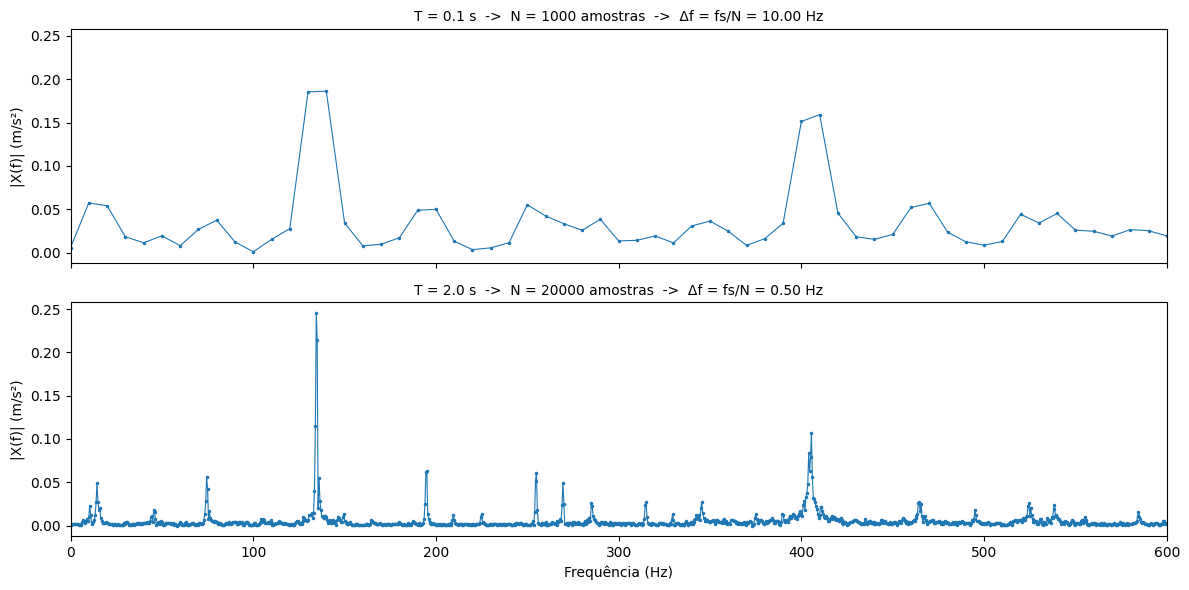

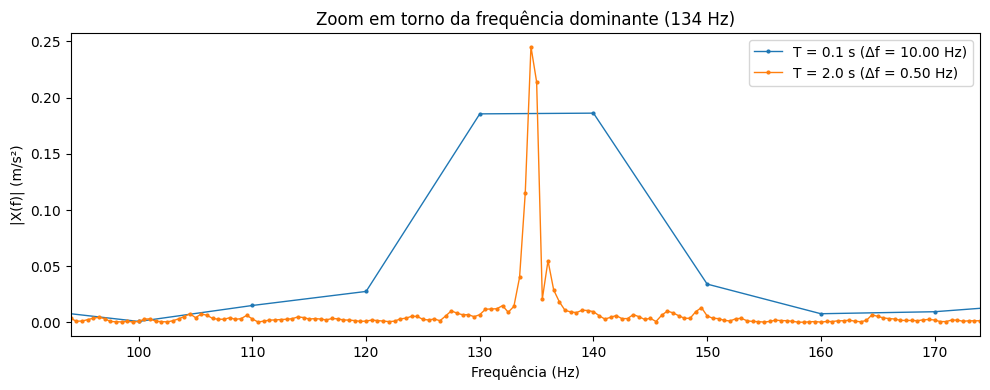

In [140]:
x = sinais['F0_SV0_SP3_C1_R1']
DURACOES = [0.1, 2.0]                            # dois trechos do mesmo registro

fig, axs = plt.subplots(len(DURACOES), 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, T in zip(axs, DURACOES):
    trecho = x[:int(T * FS)]
    f, mag = espectro(trecho, FS)
    ax.plot(f, mag, '.-', lw=0.8, ms=3)          # os pontos mostram onde a FFT calcula valores
    ax.set_title(f'T = {T} s  ->  N = {len(trecho)} amostras  ->  Δf = fs/N = {FS/len(trecho):.2f} Hz', fontsize=10)
    ax.set_ylabel('|X(f)| (m/s²)')
axs[-1].set_xlim(0, 600); axs[-1].set_xlabel('Frequência (Hz)')
plt.tight_layout(); plt.savefig('freq_resolucao.pdf'); plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
f_dom = df_freq.loc[df_freq.arquivo == 'F0_SV0_SP3_C1_R1', 'freq_dominante'].median()
for T in DURACOES:
    f, mag = espectro(x[:int(T * FS)], FS)
    ax.plot(f, mag, '.-', lw=1, ms=4, label=f'T = {T} s (Δf = {FS/int(T*FS):.2f} Hz)')
ax.set_xlim(f_dom - 40, f_dom + 40); ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('|X(f)| (m/s²)')
ax.set_title(f'Zoom em torno da frequência dominante ({f_dom:.0f} Hz)'); ax.legend()
plt.tight_layout(); plt.savefig('freq_resolucao_zoom.pdf'); plt.show()

**Resultado:** o espaçamento entre frequências é Δf = fs/N = 1/T. Com 0,1 s (N = 1 000), Δf = 10 Hz: o espectro tem poucos pontos, e o pico principal aparece como um platô entre 130 e 140 Hz, ou seja, sua frequência só é conhecida com precisão de ±5 Hz, e sua altura fica subestimada (≈ 0,185 contra ≈ 0,245 m/s²) porque a energia se divide entre pontos vizinhos. Os picos menores (73, 195 e 255 Hz) praticamente se confundem com o fundo. Com 2 s (N = 20 000), Δf = 0,5 Hz: o pico fica estreito e bem localizado em ≈ 134 Hz, e o zoom revela uma segunda componente em ≈ 136 Hz, a apenas ≈ 1,5 Hz da principal, que é invisível com 0,1 s, pois as duas caem no mesmo intervalo de 10 Hz. Portanto, trechos curtos podem fundir picos próximos e deslocar ou atenuar picos isolados. Trechos longos melhoram a resolução, mas reduzem o número de janelas disponíveis; a janela de 1 s (Δf = 1 Hz) foi adotada como compromisso.

### **3.6 Eeito da Amostragem**

Taxa original: 10000 Hz (Nyquist = 5000 Hz)
Nova taxa: 200 Hz (Nyquist = 100 Hz)
Frequência dominante 134 Hz está acima do novo Nyquist (100 Hz) -> deve aparecer em 66 Hz


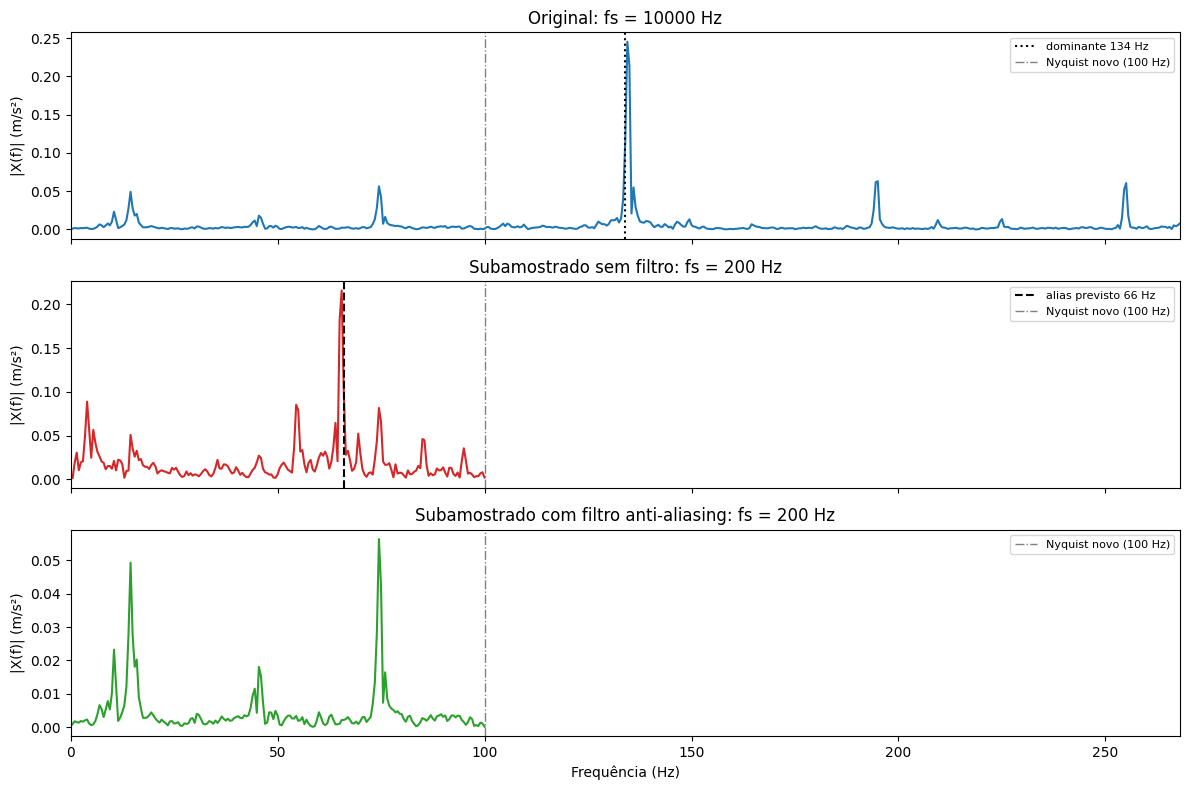

In [93]:
x = sinais['F0_SV0_SP3_C1_R1'][:int(2 * FS)]     # 2 s de sinal
f_dom = df_freq.loc[df_freq.arquivo == 'F0_SV0_SP3_C1_R1', 'freq_dominante'].median()

M_RED = int(np.ceil(FS / (1.5 * f_dom)))         # fator de redução: nova taxa ≈ 1,5 × f_dom, abaixo de 2 × f_dom
FS_NOVO = FS / M_RED                             # com f_dom ≈ 135 Hz: M = 50 -> 200 Hz
x_sub = x[::M_RED]                               # 1 amostra a cada 50, SEM filtro
x_filt = signal.resample_poly(x, 1, M_RED)       # mesma redução COM filtro anti-aliasing
f_alias = abs(f_dom - round(f_dom / FS_NOVO) * FS_NOVO)    # onde o pico deve reaparecer

print(f'Taxa original: {FS} Hz (Nyquist = {FS/2:.0f} Hz)')
print(f'Nova taxa: {FS_NOVO:.0f} Hz (Nyquist = {FS_NOVO/2:.0f} Hz)')
print(f'Frequência dominante {f_dom:.0f} Hz está acima do novo Nyquist ({FS_NOVO/2:.0f} Hz) -> deve aparecer em {f_alias:.0f} Hz')

f1, m1 = espectro(x, FS); f2, m2 = espectro(x_sub, FS_NOVO); f3, m3 = espectro(x_filt, FS_NOVO)
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axs[0].plot(f1, m1); axs[0].set_title(f'Original: fs = {FS} Hz')
axs[0].axvline(f_dom, color='k', ls=':', label=f'dominante {f_dom:.0f} Hz')
axs[1].plot(f2, m2, color='tab:red'); axs[1].set_title(f'Subamostrado sem filtro: fs = {FS_NOVO:.0f} Hz')
axs[1].axvline(f_alias, color='k', ls='--', label=f'alias previsto {f_alias:.0f} Hz')
axs[2].plot(f3, m3, color='tab:green'); axs[2].set_title(f'Subamostrado com filtro anti-aliasing: fs = {FS_NOVO:.0f} Hz')
for ax in axs:
    ax.axvline(FS_NOVO / 2, color='gray', ls='-.', lw=1, label=f'Nyquist novo ({FS_NOVO/2:.0f} Hz)')
    ax.set_ylabel('|X(f)| (m/s²)'); ax.legend(fontsize=8, loc='upper right')
axs[0].set_xlim(0, 2 * f_dom); axs[-1].set_xlabel('Frequência (Hz)')
plt.tight_layout(); plt.savefig('freq_aliasing.pdf'); plt.show()

**Resultado:** a taxa foi reduzida de 10 000 Hz para **200 Hz** (fator 50), com nova frequência de Nyquist de 100 Hz. Pelo critério de Nyquist, só componentes abaixo de fs'/2 são representadas corretamente. O pico dominante, em 134 Hz, excede esse limite e, sem filtro, reaparece em **66 Hz**, exatamente como prevê $f_a = |f - \mathrm{round}(f/f_s')\,f_s'| = |134 - 200|$, uma frequência que não existe no sinal original e que passa a ser o maior pico do espectro. Outras componentes acima de 100 Hz também "dobram" para a faixa de 0–100 Hz, criando vários picos falsos que se misturam aos verdadeiros. Com o filtro anti-aliasing aplicado antes da redução, os picos falsos desaparecem e restam apenas as componentes reais abaixo de 100 Hz (≈ 15, ≈ 45 e ≈ 74 Hz), com amplitudes próximas às do espectro original; porém, toda a informação acima de 100 Hz, incluindo o pico dominante, é perdida. A taxa original de 10 kHz é, portanto, adequada para o conteúdo espectral observado.

## **4. Comparação entre os Domínios**

Juntamos as características do tempo e da frequência, calculadas **nas mesmas janelas dos mesmos registros**, e seguimos quatro passos:

1. medimos **o quanto cada característica separa as condições** (4.1);
2. verificamos **a redundância entre elas**, pela correlação de Pearson entre janelas (4.2);
3. apresentamos **dois achados** que mostram o que cada domínio revela (4.3 e 4.4);
4. justificamos **o conjunto de características para a classificação** (4.5).

### **4.1 Quanto cada característica separa as condições**

Usamos duas medidas, sempre comparando danificada com saudável:

- **d de Cohen:** diferença entre as médias dos dois grupos, medida em desvios padrão, $d = (\bar{x}_{danif} - \bar{x}_{saud}) / s_{conjunto}$. |d| < 0,2 é desprezível, ≈ 0,5 é médio e > 0,8 é grande.
- **AUC:** probabilidade de uma janela danificada, sorteada ao acaso, ter valor maior que uma janela saudável sorteada ao acaso. 0,5 significa que a característica não separa nada (cara ou coroa); perto de 1 ou de 0, separa bem (valores maiores ou menores na danificada).

Além das características das seções 2 e 3, incluímos a **fração da potência em cada banda** (potência da banda ÷ potência total da janela), que descreve a *forma* do espectro sem depender da intensidade da vibração.

In [1]:
FEAT_TEMPO = CARAC
FEAT_FREQ = CARAC_F
df_feat = df_tempo.merge(df_freq.drop(columns=['condicao', 'F', 'SV']), on=['arquivo', 'janela'])
TODAS = FEAT_TEMPO + FEAT_FREQ

# Fração da potência em cada banda (potência da banda ÷ potência total da janela).
# Descreve a FORMA do espectro (onde a energia está), sem depender da intensidade da vibração.
FRAC_BANDAS = []
for c in COL_BANDAS:
    nome = c.replace('pot_', 'frac_')
    df_feat[nome] = df_feat[c] / df_feat['potencia']
    FRAC_BANDAS.append(nome)
COLS_D = FEAT_TEMPO + FEAT_FREQ + FRAC_BANDAS

def cohen_d(a, b):
    # diferença entre as médias (b - a) dividida pelo desvio padrão conjunto dos dois grupos
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp if sp > 0 else np.nan

def auc(a, b):
    # probabilidade de um valor de b ser maior que um valor de a (estatística U de Mann-Whitney normalizada)
    return stats.mannwhitneyu(b, a).statistic / (len(a) * len(b))

ranking = []
for c in COLS_D:
    s = df_feat.loc[df_feat.condicao == 'saudavel', c]
    d = df_feat.loc[df_feat.condicao == 'danificada', c]
    ranking.append({'caracteristica': c, 'dominio': 'tempo' if c in FEAT_TEMPO else 'frequência',
                    'media_saudavel': s.mean(), 'media_danificada': d.mean(), 'cohen_d': cohen_d(s, d), 'auc': auc(s, d)})
ranking = (pd.DataFrame(ranking).assign(abs_d=lambda t: t.cohen_d.abs())
           .sort_values('abs_d', ascending=False).reset_index(drop=True))
ranking.round(3)

,caracteristica,dominio,media_saudavel,media_danificada,cohen_d,auc,abs_d
0,frac_B2_200_335Hz,frequência,0.138,0.085,-1.381,0.274,1.381
1,pot_B3_335_600Hz,frequência,0.028,0.048,0.711,0.664,0.711
2,frac_B3_335_600Hz,frequência,0.380,0.507,0.687,0.692,0.687
3,pot_B2_200_335Hz,frequência,0.010,0.008,-0.503,0.362,0.503
4,frac_B4_600_5000Hz,frequência,0.049,0.045,-0.502,0.354,0.502
5,potencia_media,tempo,0.077,0.107,0.424,0.511,0.424
6,potencia,frequência,0.077,0.107,0.424,0.511,0.424
7,pico_a_pico,tempo,1.886,2.109,0.358,0.553,0.358
8,frac_B1_5_200Hz,frequência,0.433,0.363,-0.344,0.392,0.344
9,pico_abs,tempo,1.008,1.107,0.306,0.541,0.306


**Leitura do ranking (todas as danificadas juntas).** Com as nove falhas tratadas como uma classe só, quase nada separa bem as condições. Só a fração da potência em B2 tem efeito grande (d = −1,38; AUC = 0,27). Depois vêm a potência em B3 (d = 0,71; AUC = 0,66) e a fração em B3 (d = 0,69; AUC = 0,69). As demais ficam em |d| ≈ 0,5 ou menos.

As medidas temporais de intensidade (RMS, potência média, picos) têm d entre 0,30 e 0,42, mas AUC entre 0,51 e 0,55. Ou seja: a *média* é maior na condição danificada, mas uma janela danificada sorteada ao acaso tem praticamente a mesma chance de ter RMS maior ou menor que uma saudável. Fator de crista, centroide e entropia quase não separam (|d| < 0,2; AUC entre 0,52 e 0,56). A frequência dominante mostra o caso contrário: d = 0,07, mas AUC = 0,31, porque ela alterna entre dois picos (≈ 133 e ≈ 400 Hz) e a média não descreve bem uma distribuição com dois grupos de valores.

Esses números escondem uma coisa: a classe "danificada" reúne três grupos de falha diferentes (F1, F2 e F3). A célula seguinte repete o d de Cohen para cada grupo.

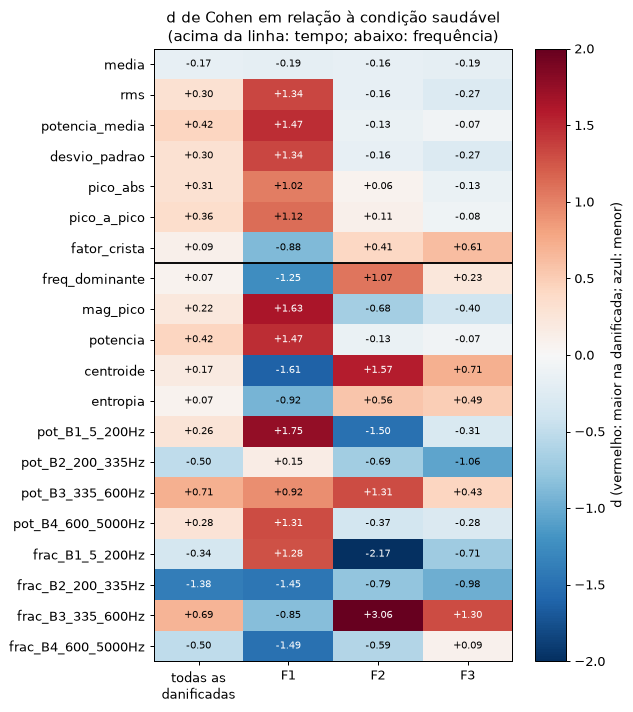

,todas,F1,F2,F3
media,-0.17,-0.19,-0.16,-0.19
rms,0.30,1.34,-0.16,-0.27
potencia_media,0.42,1.47,-0.13,-0.07
desvio_padrao,0.30,1.34,-0.16,-0.27
pico_abs,0.31,1.02,0.06,-0.13
pico_a_pico,0.36,1.12,0.11,-0.08
fator_crista,0.09,-0.88,0.41,0.61
freq_dominante,0.07,-1.25,1.07,0.23
mag_pico,0.22,1.63,-0.68,-0.40
potencia,0.42,1.47,-0.13,-0.07


In [2]:
# d de Cohen contra a condição saudável: todas as danificadas juntas e cada grupo de falha separado
saud = df_feat[df_feat.F == 'F0']
comparacoes = {'todas': df_feat[df_feat.F != 'F0'], 'F1': df_feat[df_feat.F == 'F1'],
               'F2': df_feat[df_feat.F == 'F2'], 'F3': df_feat[df_feat.F == 'F3']}
d_grupos = pd.DataFrame({nome: {c: cohen_d(saud[c], grupo[c]) for c in COLS_D}
                         for nome, grupo in comparacoes.items()})

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(d_grupos.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(4), ['todas as\ndanificadas', 'F1', 'F2', 'F3'])
ax.set_yticks(range(len(COLS_D)), COLS_D)
for i in range(len(COLS_D)):
    for j in range(4):
        v = d_grupos.values[i, j]
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 1.2 else 'black')
ax.axhline(len(FEAT_TEMPO) - 0.5, color='k', lw=1.5)          # separa tempo (acima) de frequência (abaixo)
ax.set_title('d de Cohen em relação à condição saudável\n(acima da linha: tempo; abaixo: frequência)')
plt.colorbar(im, label='d (vermelho: maior na danificada; azul: menor)')
plt.tight_layout(); plt.savefig('comp_d_grupos.pdf'); plt.show()
d_grupos.round(2)

**Leitura do mapa.** Cada grupo de falha altera o sinal de um jeito, e os efeitos têm sentidos opostos:

- **F1** aumenta a intensidade (RMS: d = +1,34; pico absoluto: +1,02) e concentra a energia nas baixas frequências (fração em B1: +1,28; centroide: −1,61).
- **F2** não muda a intensidade (RMS: d = −0,16), mas tem muito mais energia em 335–600 Hz (fração em B3: +3,06; fração em B1: −2,17; centroide: +1,57).
- **F3** fica entre os dois: intensidade um pouco menor (RMS: −0,27) e mais energia em B3 (+1,30).

Somando os três grupos, os efeitos se cancelam; por isso o RMS tem d = 0,30 e o centroide, 0,17 na coluna "todas". **Nenhum domínio é superior em todos os casos:** as medidas de intensidade (tempo) são as que mais destacam F1, e as de distribuição da energia (frequência) são as que mais destacam F2 e F3. A única característica com efeito de mesmo sentido nos três grupos é a fração em B2 (−1,45, −0,79 e −0,98; −1,38 no conjunto).

*Cuidado na leitura:* o d de Cohen descreve o tamanho da diferença entre as janelas. As 720 janelas vêm de apenas 12 registros (3 saudáveis), então ele não equivale a um teste estatístico com 720 observações independentes.

### **4.2 Redundância entre características**

Correlação do RMS com as frações por banda: {'frac_B1_5_200Hz': 0.4, 'frac_B2_200_335Hz': -0.39, 'frac_B3_335_600Hz': -0.31, 'frac_B4_600_5000Hz': -0.89}


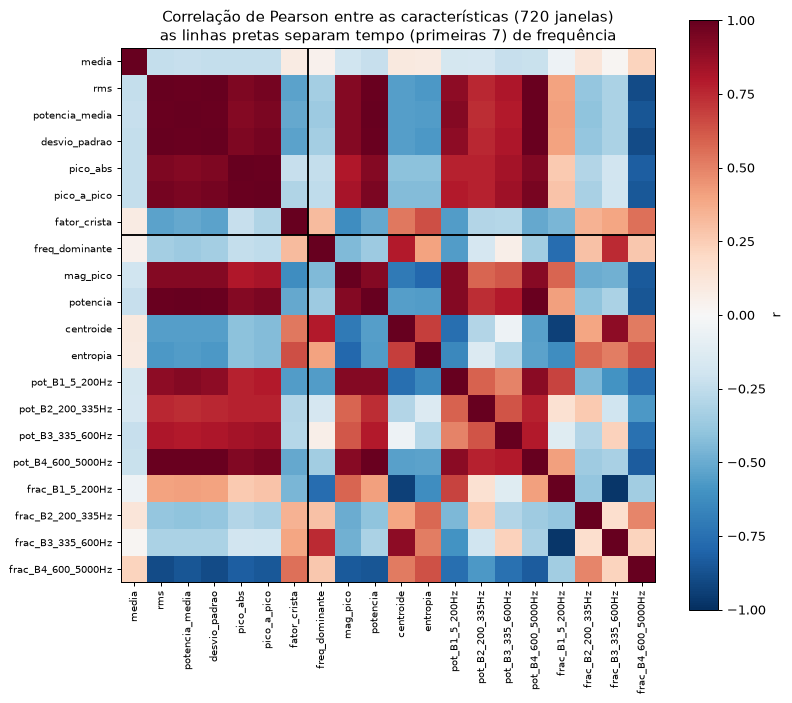

,característica 1,característica 2,r
1,rms,desvio_padrao,1.000
11,potencia_media,potencia,1.000
18,desvio_padrao,pot_B4_600_5000Hz,0.991
6,rms,pot_B4_600_5000Hz,0.991
19,pico_abs,pico_a_pico,0.991
28,potencia,pot_B4_600_5000Hz,0.990
13,potencia_media,pot_B4_600_5000Hz,0.990
5,rms,potencia,0.989
0,rms,potencia_media,0.989
17,desvio_padrao,potencia,0.989


In [3]:
corr_todas = df_feat[COLS_D].corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_todas.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(COLS_D)), COLS_D, rotation=90, fontsize=8)
ax.set_yticks(range(len(COLS_D)), COLS_D, fontsize=8)
n_t = len(FEAT_TEMPO)
ax.axhline(n_t - 0.5, color='k', lw=1.5); ax.axvline(n_t - 0.5, color='k', lw=1.5)   # separa tempo de frequência
ax.set_title('Correlação de Pearson entre as características (720 janelas)\n'
             'as linhas pretas separam tempo (primeiras 7) de frequência')
plt.colorbar(im, label='r'); plt.tight_layout(); plt.savefig('comp_correlacao.pdf'); plt.show()

# pares praticamente redundantes (|r| >= 0,90)
pares = [(a, b, corr_todas.loc[a, b]) for i, a in enumerate(COLS_D) for b in COLS_D[i+1:]
         if abs(corr_todas.loc[a, b]) >= 0.90]
print('Correlação do RMS com as frações por banda:', corr_todas.loc['rms', FRAC_BANDAS].round(2).to_dict())
pd.DataFrame(pares, columns=['característica 1', 'característica 2', 'r']).sort_values('r', ascending=False).round(3)

**Leitura.** Existe um grande bloco de características que medem a mesma coisa, a **intensidade** da vibração: RMS, desvio padrão, potência média, potência total do espectro, pico a pico, pico absoluto, magnitude do pico dominante e as potências absolutas em B1 e B4 (r entre 0,90 e 1,00). Duas dessas igualdades são esperadas pela teoria: RMS ≈ desvio padrão porque a média é ≈ 0 (seção 2.4), e a potência média no tempo é igual à potência total do espectro (relação de Parseval, r = 1,00). Ou seja, **a potência espectral total não acrescenta nada ao RMS**: é a mesma informação vista pelo outro domínio.

As potências absolutas por banda também acompanham a intensidade (r de 0,76 a 0,99 com o RMS). Já as **frações** em B1, B2 e B3 dependem pouco dela (|r| ≤ 0,40 com o RMS) e por isso são mais adequadas para descrever a forma do espectro. A exceção é a fração em B4 (r = −0,89 com o RMS): ela cai quando a vibração é forte, ou seja, também mede intensidade. Entre as frações, B1 e B3 são quase o espelho uma da outra (r = −0,97), e o centroide resume as duas (r = −0,94 com a fração em B1 e +0,90 com a fração em B3).

Trazem informação própria, com correlação apenas moderada com o bloco de intensidade (|r| entre 0,3 e 0,6): o fator de crista, a entropia espectral e a fração em B2.

### **4.3 Achado 1: mesma intensidade, espectros diferentes**

Para comparar os dois domínios nos mesmos registros, escolhemos duas janelas com praticamente o mesmo RMS, uma saudável e uma do grupo F2, e mostramos as duas no tempo e na frequência. O terceiro gráfico coloca as 720 janelas no plano RMS (tempo) × fração da potência em B3 (frequência).

Janelas com RMS entre 0.239 e 0.309 m/s² (faixa central das saudáveis):


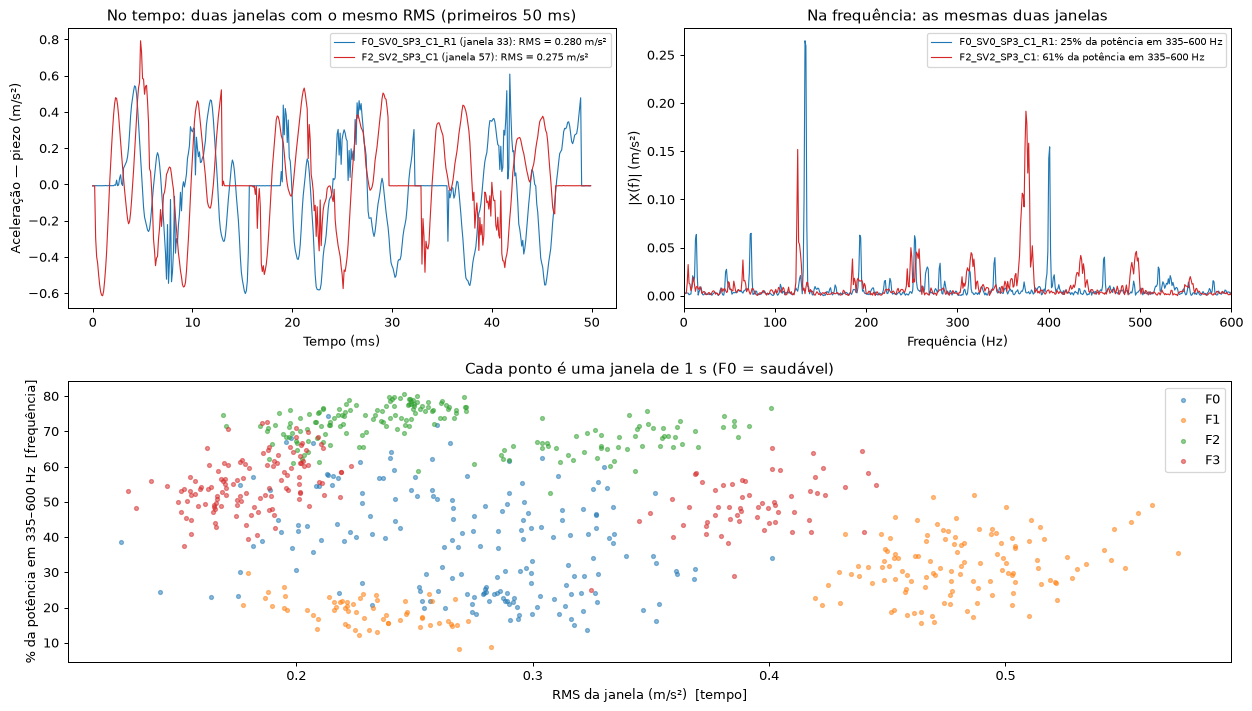

,n_janelas,rms_medio,frac_B3_media
F,,,
F0,90,0.277,0.361
F1,19,0.259,0.167
F2,65,0.262,0.737


In [4]:
# escolhe uma janela saudável com RMS típico e a janela do grupo F2 com o RMS mais próximo
rms_mediano = saud['rms'].median()
i_s = (saud['rms'] - rms_mediano).abs().idxmin()
f2 = df_feat[df_feat.F == 'F2']
i_d = (f2['rms'] - df_feat.loc[i_s, 'rms']).abs().idxmin()

fig = plt.figure(figsize=(14, 8))
ax0 = fig.add_subplot(2, 2, 1); ax1 = fig.add_subplot(2, 2, 2); ax2 = fig.add_subplot(2, 1, 2)
t_ms = np.arange(N) / FS * 1000
for i, cond in [(i_s, 'saudavel'), (i_d, 'danificada')]:
    r = df_feat.loc[i]
    ax0.plot(t_ms[:500], janelas[i][:500], lw=0.9, color=CORES[cond],
             label=f"{r['arquivo']} (janela {r['janela']}): RMS = {r['rms']:.3f} m/s²")
    ax1.plot(f_jan, espectros[i], lw=0.9, color=CORES[cond],
             label=f"{r['arquivo']}: {100 * r['frac_B3_335_600Hz']:.0f}% da potência em 335–600 Hz")
ax0.set_xlabel('Tempo (ms)'); ax0.set_ylabel('Aceleração — piezo (m/s²)'); ax0.legend(fontsize=8, loc='upper right')
ax0.set_title('No tempo: duas janelas com o mesmo RMS (primeiros 50 ms)')
ax1.set_xlim(0, 600); ax1.set_xlabel('Frequência (Hz)'); ax1.set_ylabel('|X(f)| (m/s²)'); ax1.legend(fontsize=8)
ax1.set_title('Na frequência: as mesmas duas janelas')
for f_cod in CORES_F:
    g = df_feat[df_feat.F == f_cod]
    ax2.scatter(g['rms'], 100 * g['frac_B3_335_600Hz'], s=10, alpha=0.5, color=CORES_F[f_cod], label=f_cod)
ax2.set_xlabel('RMS da janela (m/s²)  [tempo]'); ax2.set_ylabel('% da potência em 335–600 Hz  [frequência]')
ax2.set_title('Cada ponto é uma janela de 1 s (F0 = saudável)'); ax2.legend()
plt.tight_layout(); plt.savefig('comp_achado1.pdf'); plt.show()

# janelas com RMS na faixa central das saudáveis: quanto da potência está em B3, por grupo de falha?
q1, q3 = saud['rms'].quantile([0.25, 0.75])
mesma_faixa = df_feat[(df_feat['rms'] >= q1) & (df_feat['rms'] <= q3)]
print(f'Janelas com RMS entre {q1:.3f} e {q3:.3f} m/s² (faixa central das saudáveis):')
(mesma_faixa.groupby('F').agg(n_janelas=('rms', 'size'), rms_medio=('rms', 'mean'),
                              frac_B3_media=('frac_B3_335_600Hz', 'mean')).round(3))

**Achado 1.** Pelas medidas do tempo, as duas janelas são equivalentes: RMS de 0,280 e 0,275 m/s². Na frequência, elas são muito diferentes: na saudável domina o pico de ≈ 133 Hz, e só 25% da potência está entre 335 e 600 Hz; na danificada a maior componente é a de ≈ 375 Hz, e 61% da potência está nessa banda.

O gráfico de dispersão mostra que isso vale para o conjunto. Entre as janelas com RMS na faixa central das saudáveis (0,24 a 0,31 m/s²), a fração média em B3 é 36% nas saudáveis, 17% em F1 e 74% em F2. No eixo horizontal (RMS), só as janelas de dois registros de F1 se afastam das saudáveis; no eixo vertical (fração em B3), quem se afasta é F2. **O tempo mede quanto o sinal vibra; a frequência mostra onde essa energia está.** Duas condições podem ter a mesma intensidade e espectros diferentes, e só a análise em frequência as distingue.

*Observação:* os trechos quase planos visíveis no gráfico temporal (≈ 3 ms a cada ≈ 16,7 ms) aparecem em todos os registros analisados, saudáveis e danificados, com a mesma periodicidade.

### **4.4 Achado 2: a posição dos picos acompanha a tensão da bateria**

Na seção 3, os picos principais da condição danificada aparecem em frequências um pouco menores (133 → 128 Hz). Essa diferença é invisível no tempo: corresponde a uma mudança de ≈ 0,3 ms no período da oscilação (7,5 → 7,8 ms). Antes de atribuí-la ao defeito, verificamos uma condição de operação que os próprios arquivos registram: a tensão da bateria (`BatteryVolt`).

Medimos, em cada janela, a frequência do maior pico entre 100 e 160 Hz e comparamos a média de cada registro com a tensão média da bateria. Como verificação auxiliar, incluímos os 9 registros danificados de SP3/C2: são as mesmas falhas e severidades, gravadas com outra tensão de bateria. Eles são usados **somente** nesta verificação.

Correlação com a tensão da bateria, um ponto por registro (21 registros):
f_pico     1.00
rms       -0.11
frac_B3   -0.59


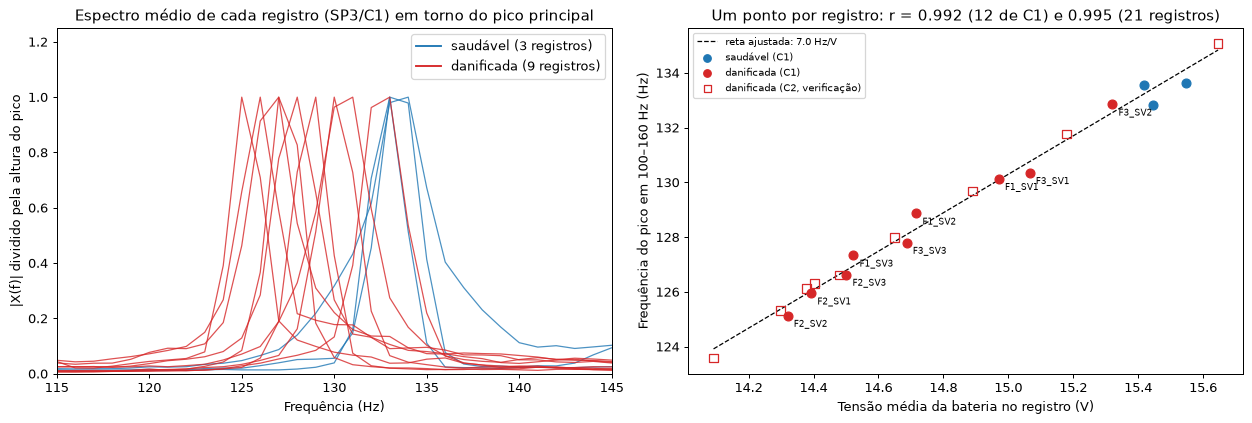

bateria_V         f_pico        
C             C1     C2      C1      C2
falha                                  
F1_SV1     14.97  15.65  130.13  135.07
F1_SV2     14.72  15.18  128.87  131.77
F1_SV3     14.52  14.89  127.33  129.68
F2_SV1     14.39  14.65  125.95  128.00
F2_SV2     14.32  14.48  125.13  126.62
F2_SV3     14.50  14.38  126.63  126.13
F3_SV1     15.07  14.30  130.35  125.33
F3_SV2     15.32  14.09  132.85  123.58
F3_SV3     14.69  14.40  127.80  126.30

In [5]:
# frequência do maior pico entre 100 e 160 Hz em cada janela
# (busca restrita a essa faixa para não alternar com o pico de ~400 Hz, como acontece com a frequência dominante)
faixa = (f_jan >= 100) & (f_jan <= 160)
df_feat['f_pico_100_160'] = f_jan[faixa][espectros[:, faixa].argmax(axis=1)]

# um ponto por registro. BatteryVolt usa a base de tempo da IMU (não sincronizada com o piezo),
# por isso comparamos a média do registro, e não janela a janela.
reg = (df_feat.groupby(['arquivo', 'condicao', 'F'])
       .agg(f_pico=('f_pico_100_160', 'mean'), rms=('rms', 'mean'), frac_B3=('frac_B3_335_600Hz', 'mean')).reset_index())
reg['bateria_V'] = [np.mean(loadmat(c, squeeze_me=True)['BatteryVolt'])
                    for c in sel.set_index('arquivo').loc[reg['arquivo'], 'caminho']]
reg['C'] = 'C1'

# verificação auxiliar: mesmas falhas e severidades em SP3/C2 (usadas somente aqui)
linhas_c2 = []
for _, r in tabela[(tabela['SP'] == 'SP3') & (tabela['C'] == 'C2') & (tabela['F'] != 'F0')].iterrows():
    d = loadmat(r['caminho'], squeeze_me=True, struct_as_record=False)
    x = d['AccData'].Vib_Data
    jan = [x[k*N:(k+1)*N] for k in range(len(x) // N)]
    cf = pd.DataFrame([caracteristicas_freq(w, FS) for w in jan])
    linhas_c2.append({'arquivo': r['arquivo'], 'condicao': 'danificada', 'F': r['F'],
                      'f_pico': np.mean([f_jan[faixa][espectro(w, FS)[1][faixa].argmax()] for w in jan]),
                      'rms': np.mean([np.sqrt(np.mean(w**2)) for w in jan]),
                      'frac_B3': (cf['pot_B3_335_600Hz'] / cf['potencia']).mean(),
                      'bateria_V': np.mean(d['BatteryVolt']), 'C': 'C2'})
reg_todos = pd.concat([reg, pd.DataFrame(linhas_c2)], ignore_index=True)

r_c1 = reg['bateria_V'].corr(reg['f_pico'])
r_todos = reg_todos['bateria_V'].corr(reg_todos['f_pico'])
a, b = np.polyfit(reg_todos['bateria_V'], reg_todos['f_pico'], 1)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for _, r in reg.iterrows():
    media = espectros[(df_janelas['arquivo'] == r['arquivo']).values].mean(axis=0)
    axs[0].plot(f_jan, media / media[faixa].max(), lw=1, color=CORES[r['condicao']], alpha=0.8)
axs[0].plot([], [], color=CORES['saudavel'], label='saudável (3 registros)')
axs[0].plot([], [], color=CORES['danificada'], label='danificada (9 registros)')
axs[0].set_xlim(115, 145); axs[0].set_ylim(0, 1.25); axs[0].legend(loc='upper right')
axs[0].set_xlabel('Frequência (Hz)'); axs[0].set_ylabel('|X(f)| dividido pela altura do pico')
axs[0].set_title('Espectro médio de cada registro (SP3/C1) em torno do pico principal')

for _, r in reg_todos.iterrows():
    cheio = r['C'] == 'C1'
    axs[1].scatter(r['bateria_V'], r['f_pico'], s=50, marker='o' if cheio else 's', zorder=3,
                   facecolors=CORES[r['condicao']] if cheio else 'none', edgecolors=CORES[r['condicao']])
    if cheio and r['F'] != 'F0':
        axs[1].annotate(r['arquivo'].replace('_SP3_C1', ''), (r['bateria_V'], r['f_pico']), fontsize=7,
                        xytext=(5, -9), textcoords='offset points')
xv = np.array([reg_todos['bateria_V'].min(), reg_todos['bateria_V'].max()])
axs[1].plot(xv, a * xv + b, 'k--', lw=1, label=f'reta ajustada: {a:.1f} Hz/V')
axs[1].scatter([], [], marker='o', color=CORES['saudavel'], label='saudável (C1)')
axs[1].scatter([], [], marker='o', color=CORES['danificada'], label='danificada (C1)')
axs[1].scatter([], [], marker='s', facecolors='none', edgecolors=CORES['danificada'], label='danificada (C2, verificação)')
axs[1].set_xlabel('Tensão média da bateria no registro (V)'); axs[1].set_ylabel('Frequência do pico em 100–160 Hz (Hz)')
axs[1].set_title(f'Um ponto por registro: r = {r_c1:.3f} (12 de C1) e {r_todos:.3f} (21 registros)'); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('comp_achado2.pdf'); plt.show()

print('Correlação com a tensão da bateria, um ponto por registro (21 registros):')
print(reg_todos[['f_pico', 'rms', 'frac_B3']].corrwith(reg_todos['bateria_V']).round(2).to_string())

# a mesma falha e severidade, gravada em C1 e em C2
reg_todos['falha'] = reg_todos['arquivo'].str[:6]
(reg_todos[reg_todos['F'] != 'F0'].pivot(index='falha', columns='C', values=['bateria_V', 'f_pico']).round(2))

**Achado 2.** A frequência do pico acompanha a tensão da bateria quase perfeitamente: r = 0,992 nos 12 registros de C1 e r = 0,995 nos 21 registros (≈ 7 Hz por volt).

- Os três registros saudáveis foram gravados com a bateria mais carregada (15,4 a 15,5 V) e têm o pico em ≈ 133 Hz. Os danificados foram gravados com 14,3 a 15,3 V e têm o pico entre 125 e 133 Hz.
- O registro danificado gravado com tensão próxima à dos saudáveis (F3_SV2, 15,3 V) tem o pico no mesmo lugar que eles (132,9 Hz).
- A mesma falha, gravada com tensões diferentes, tem o pico em lugares diferentes: F1_SV1 está em 130,1 Hz com 14,97 V (C1) e em 135,1 Hz com 15,65 V (C2), acima dos saudáveis.
- O pico de ≈ 400 Hz se move junto, porque fica sempre em ≈ 3 vezes a frequência do primeiro.

Portanto, **o deslocamento dos picos entre as condições é explicado pela tensão da bateria no momento da gravação e, com estes dados, não pode ser atribuído ao defeito.** O padrão é compatível com uma variação da velocidade de rotação dos motores com a tensão, mas o dataset não informa a rotação; por isso não afirmamos essa causa.

Este é um caso em que a frequência revela algo que o tempo não mostra e, ao mesmo tempo, um aviso: uma característica espectral pode separar as condições por um motivo que não é o defeito. A fração da potência em B3 também tem alguma relação com a tensão (r ≈ −0,6, um ponto por registro), bem mais fraca; registramos isso como **risco de confusão**, não como conclusão. O RMS não tem essa relação (r ≈ −0,1).

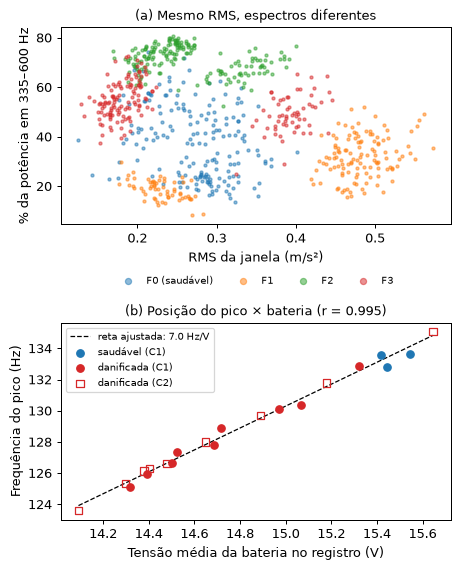

In [6]:
# figura-resumo para o relatório: os dois achados, um sobre o outro (largura de uma coluna)
fig, axs = plt.subplots(2, 1, figsize=(5.2, 6.4))
for f_cod in CORES_F:
    g = df_feat[df_feat.F == f_cod]
    axs[0].scatter(g['rms'], 100 * g['frac_B3_335_600Hz'], s=6, alpha=0.5, color=CORES_F[f_cod],
                   label='F0 (saudável)' if f_cod == 'F0' else f_cod)
axs[0].set_xlabel('RMS da janela (m/s²)'); axs[0].set_ylabel('% da potência em 335–600 Hz')
axs[0].set_title('(a) Mesmo RMS, espectros diferentes', fontsize=10)
axs[0].legend(fontsize=8, markerscale=2, ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.36), frameon=False)
for _, r in reg_todos.iterrows():
    cheio = r['C'] == 'C1'
    axs[1].scatter(r['bateria_V'], r['f_pico'], s=35, marker='o' if cheio else 's', zorder=3,
                   facecolors=CORES[r['condicao']] if cheio else 'none', edgecolors=CORES[r['condicao']])
axs[1].plot(xv, a * xv + b, 'k--', lw=1, label=f'reta ajustada: {a:.1f} Hz/V')
axs[1].scatter([], [], marker='o', color=CORES['saudavel'], label='saudável (C1)')
axs[1].scatter([], [], marker='o', color=CORES['danificada'], label='danificada (C1)')
axs[1].scatter([], [], marker='s', facecolors='none', edgecolors=CORES['danificada'], label='danificada (C2)')
axs[1].set_xlabel('Tensão média da bateria no registro (V)'); axs[1].set_ylabel('Frequência do pico (Hz)')
axs[1].set_title(f'(b) Posição do pico × bateria (r = {r_todos:.3f})', fontsize=10); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig('09_notebook_comparacao.png', dpi=200); plt.show()

### **4.5 Características mais úteis e conjunto para a classificação**

**Quais características de cada domínio são mais úteis para separar as condições?**

- **Tempo:** o RMS, que representa todo o bloco de intensidade e é o que mais destaca F1, e o fator de crista, a única medida temporal que muda em F2 e F3 (d = +0,41 e +0,61) e que é pouco correlacionada com o RMS.
- **Frequência:** as frações de potência em B2 e B3 e a entropia espectral. São as que mais destacam F2 e F3, justamente os grupos que a intensidade não distingue.
- **Nenhum domínio é suficiente sozinho:** o tempo enxerga F1 e quase não enxerga F2; a frequência enxerga F2 e F3 e é menos sensível a F1. A expectativa para a 2ª entrega é que o modelo combinado (C) aproveite as duas informações, o que será verificado com a divisão de treino e teste por registro.

**Conjunto proposto para a classificação (2ª entrega):**

| Modelo | Características |
|---|---|
| A (tempo) | RMS, fator de crista |
| B (frequência) | fração da potência em B2, fração da potência em B3, entropia espectral |
| C (combinado) | as cinco acima |

**O que ficou de fora e por quê** (todas continuam extraídas, apresentadas e analisadas nas seções 2 e 3):

- desvio padrão, potência média, potência total do espectro, pico a pico, pico absoluto e magnitude do pico dominante: redundantes com o RMS (r ≥ 0,92); além disso, pico absoluto = RMS × fator de crista;
- potências absolutas por banda: acompanham a intensidade; foram substituídas pelas frações;
- fração em B1 e centroide: redundantes com a fração em B3 (r = −0,97 e +0,90); fração em B4: menos de 5% da potência e ligada ao RMS (r = −0,89);
- média: ≈ 0 e não separa as condições (|d| < 0,2);
- frequência dominante: alterna entre ≈ 133 e ≈ 400 Hz de uma janela para outra (seção 3) e sua posição acompanha a bateria (achado 2);
- frequência do pico em 100–160 Hz: separaria bem as janelas, mas pelo motivo errado (a bateria). Fica apenas como ferramenta de interpretação.

**Limitações.** (i) As 720 janelas vêm de 12 registros, e só 3 são saudáveis; os registros saudáveis diferem entre si (R1 tem 66% da potência em B1; R2 e R3, ≈ 32%), em grau parecido com a diferença entre condições. (ii) A tensão da bateria difere sistematicamente entre saudáveis e danificados e pode influenciar as características espectrais. (iii) O significado do código C não é documentado. Por isso, os resultados valem para este recorte (SP3/C1) e a separação observada entre janelas não deve ser lida como capacidade de detectar o defeito em novos ensaios.

## **5. Investigação adicional**

**Pergunta:** *As vibrações medidas nos eixos X, Y e Z da IMU têm as mesmas características, e a diferença entre hélice saudável e danificada aparece igualmente nos três eixos?*

**Justificativa:** a análise principal (seções 2 a 4) usou o acelerômetro piezoelétrico, que mede a vibração em uma única direção. A IMU do drone mede a aceleração em três direções ao mesmo tempo. Verificar se os três eixos registram a vibração da mesma forma, e em qual direção o defeito se manifesta mais, indica qual eixo seria mais útil para detectar falhas nas hélices. Essa é uma das perguntas sugeridas pelo enunciado do projeto.

**Método:** foram usados os mesmos 12 registros da análise principal (SP3, C1), agora com o sinal `IMUData.Vib_Data` (fs = 1 kHz, Nyquist = 500 Hz), eixos x, y e z. Diferentemente do piezo, os sinais da IMU passaram por um filtro passa-altas Butterworth de 4ª ordem com corte em 5 Hz (`filtfilt`), para remover a gravidade, que no eixo z gera uma componente média de ≈ 9,7 m/s² e inflaria o RMS (ver seção 2.4). Como a IMU inicia a gravação antes de os motores entrarem em regime, foram descartadas as janelas com RMS inferior a 30% da mediana do registro. Os sinais foram divididos em janelas de 1 s (N = 1 000), e as características foram calculadas com as mesmas funções da análise principal. A banda B4 (> 600 Hz) não existe para a IMU, e a B3 vai só até 500 Hz.

**Organização da seção:** primeiro, comparamos o espectro do piezo com o dos três eixos da IMU em um mesmo registro e verificamos o início da gravação da IMU. Em seguida, calculamos as características temporais e espectrais por eixo e condição, comparamos os espectros médios de cada eixo e medimos, pelo d de Cohen, o quanto cada eixo separa as condições saudável e danificada. A resposta à pergunta é apresentada ao final, com base nesses resultados.

###  **5.1 Verificação auxiliar: escolha do sensor (piezo × IMU)**

*Estes gráficos não fazem parte da análise espectral principal, que usa apenas o piezo. Eles comparam os dois sensores no mesmo registro, o que justifica a escolha feita na seção 1.2, e mostram que a IMU inicia a gravação antes de os motores entrarem em regime.*

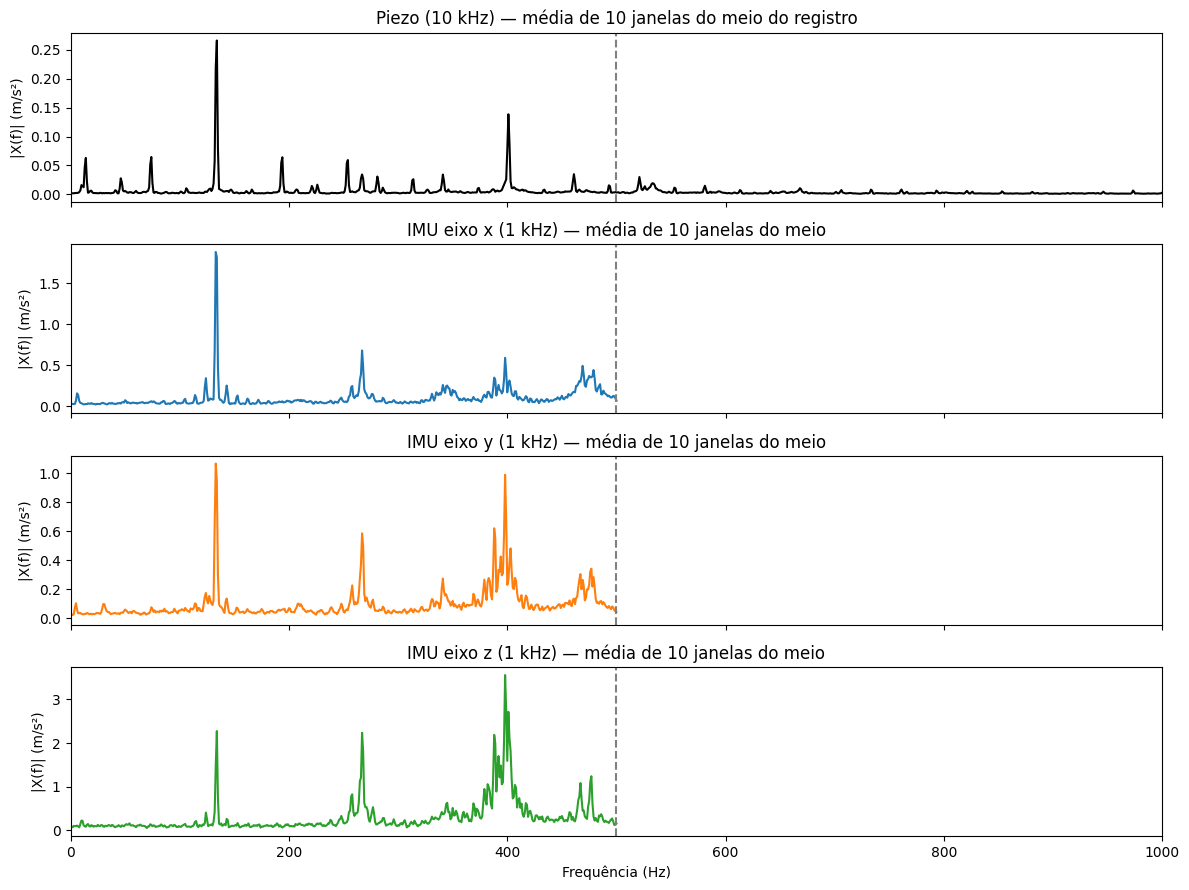

In [103]:
caminho = sel.loc[sel['arquivo'] == 'F0_SV0_SP3_C1_R1', 'caminho'].iloc[0]
d = loadmat(caminho, squeeze_me=True, struct_as_record=False)

def espectro_medio(x, fs, n_janelas=10):
    # média dos espectros de n janelas de 1 s, tiradas do MEIO do registro
    N = int(fs)
    meio = len(x) // 2
    inicio = meio - (n_janelas // 2) * N
    specs = [espectro(x[inicio + k*N : inicio + (k+1)*N], fs)[1] for k in range(n_janelas)]
    f = np.fft.rfftfreq(N, d=1/fs)
    return f, np.mean(specs, axis=0)

fig, axs = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
f, m = espectro_medio(d['AccData'].Vib_Data, 10000)
axs[0].plot(f, m, color='k'); axs[0].set_title('Piezo (10 kHz) — média de 10 janelas do meio do registro')
for i, eixo in enumerate(['x', 'y', 'z']):
    f, m = espectro_medio(d['IMUData'].Vib_Data[i], 1000)
    axs[i+1].plot(f, m, color=f'C{i}'); axs[i+1].set_title(f'IMU eixo {eixo} (1 kHz) — média de 10 janelas do meio')
for ax in axs: ax.axvline(500, color='gray', ls='--'); ax.set_ylabel('|X(f)| (m/s²)')
axs[-1].set_xlim(0, 1000); axs[-1].set_xlabel('Frequência (Hz)')
plt.tight_layout(); plt.savefig('sensores_piezo_imu.pdf'); plt.show()

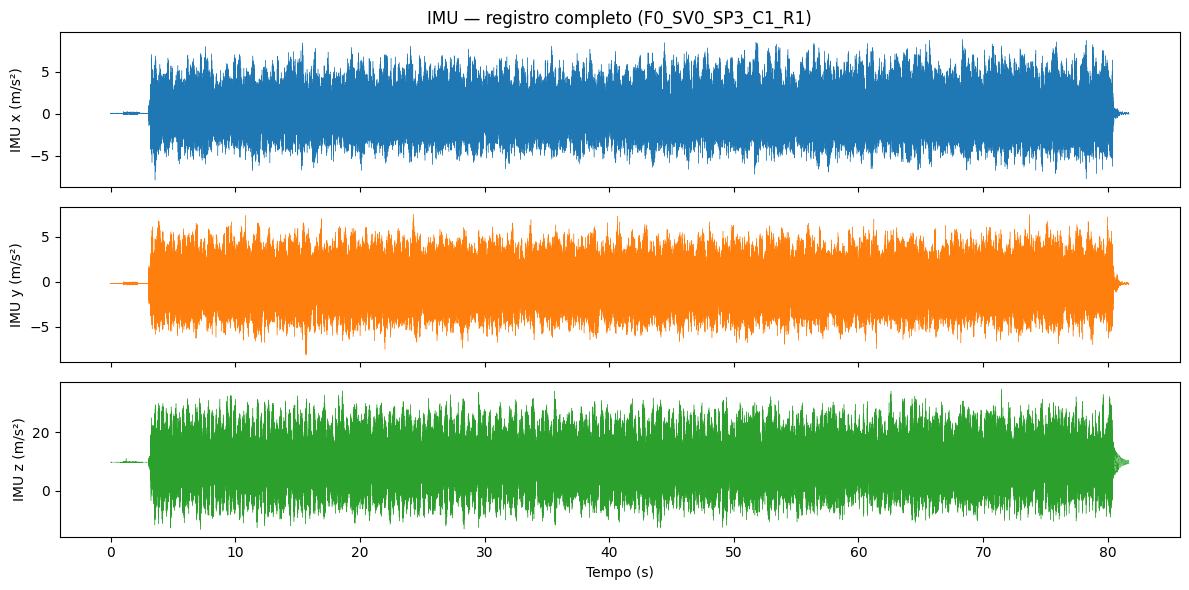

In [85]:
arq = 'F0_SV0_SP3_C1_R1'
caminho = sel.loc[sel['arquivo'] == arq, 'caminho'].iloc[0]
imu = loadmat(caminho, squeeze_me=True, struct_as_record=False)['IMUData']

fig, axs = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for i, eixo in enumerate(['x', 'y', 'z']):
    axs[i].plot(imu.t, imu.Vib_Data[i], lw=0.3, color=f'C{i}')
    axs[i].set_ylabel(f'IMU {eixo} (m/s²)')
axs[0].set_title(f'IMU — registro completo ({arq})')
axs[-1].set_xlabel('Tempo (s)')
plt.tight_layout(); plt.savefig('imu_registro_completo.pdf'); plt.show()

### **5.2 Características por eixo e condição**

In [109]:
FS_IMU = 1000
N_IMU = int(DUR_JANELA * FS_IMU)                                # 1 s = 1000 amostras
b_imu, a_imu = signal.butter(4, 5, btype='highpass', fs=FS_IMU) # passa-altas de 5 Hz (remove a gravidade)
EIXOS = ['x', 'y', 'z']

linhas_imu, espectros_imu = [], []
descartadas = []                                                # para mostrar quantas janelas foram removidas
for _, r in sel.iterrows():
    imu = loadmat(r['caminho'], squeeze_me=True, struct_as_record=False)['IMUData']
    assert imu.samplingRate == FS_IMU
    for e, eixo in enumerate(EIXOS):
        bruto = imu.Vib_Data[e]
        x = signal.filtfilt(b_imu, a_imu, bruto)

        # RMS de cada janela, para identificar o trecho com o motor parado
        n_jan = len(x) // N_IMU
        rms_jan = np.array([np.sqrt(np.mean(x[k*N_IMU:(k+1)*N_IMU]**2)) for k in range(n_jan)])
        ativas = rms_jan > 0.3 * np.median(rms_jan)      # descarta janelas com motor parado (RMS muito baixo)
        descartadas.append({'arquivo': r['arquivo'], 'eixo': eixo,
                            'janelas_total': n_jan, 'descartadas': int((~ativas).sum())})

        for k in np.where(ativas)[0]:
            w = x[k * N_IMU:(k + 1) * N_IMU]
            linhas_imu.append({'arquivo': r['arquivo'], 'condicao': r['condicao'], 'F': r['F'], 'eixo': eixo,
                               'janela': k, 'media_bruta': bruto[k * N_IMU:(k + 1) * N_IMU].mean(),
                               **caracteristicas_tempo(w), **caracteristicas_freq(w, FS_IMU)})
            espectros_imu.append(espectro(w, FS_IMU)[1])

df_imu = pd.DataFrame(linhas_imu)
espectros_imu = np.array(espectros_imu)
f_imu = np.fft.rfftfreq(N_IMU, d=1 / FS_IMU)

df_descartadas = pd.DataFrame(descartadas)
print(len(df_imu), 'janelas usadas (registros × eixos) |',
      df_descartadas['descartadas'].sum(), 'janelas descartadas por motor parado')
df_imu.groupby(['eixo', 'condicao']).size().unstack()

2818 janelas usadas (registros × eixos) | 101 janelas descartadas por motor parado


condicao,danificada,saudavel
eixo,,
x,703,237
y,703,237
z,701,237


In [110]:
COLS_INV = ['media_bruta', 'rms', 'desvio_padrao', 'fator_crista', 'freq_dominante', 'centroide', 'entropia']
tabela_eixos = df_imu.groupby(['eixo', 'condicao'])[COLS_INV].mean().round(3)
tabela_eixos

media_bruta    rms  desvio_padrao  fator_crista  \
eixo condicao                                                      
x    danificada        0.002  2.536          2.536         2.900   
     saudavel         -0.038  2.267          2.267         2.932   
y    danificada       -0.211  2.666          2.666         2.858   
     saudavel         -0.116  1.964          1.964         2.924   
z    danificada        9.725  7.295          7.295         2.694   
     saudavel          9.806  5.502          5.502         2.821   

                 freq_dominante  centroide  entropia  
eixo condicao                                         
x    danificada         188.105    290.180     0.620  
     saudavel           211.414    280.701     0.596  
y    danificada         146.716    242.038     0.556  
     saudavel           228.342    272.928     0.607  
z    danificada         367.384    346.308     0.614  
     saudavel           303.321    319.842     0.594

In [107]:
d_eixos = pd.DataFrame({eixo: {c: cohen_d(df_imu[(df_imu.eixo == eixo) & (df_imu.condicao == 'saudavel')][c],
                                          df_imu[(df_imu.eixo == eixo) & (df_imu.condicao == 'danificada')][c])
                               for c in ['rms', 'fator_crista', 'centroide', 'entropia'] + COL_BANDAS[:3]}
                        for eixo in EIXOS})
print("d de Cohen (danificada vs saudável) em cada eixo:")
d_eixos.round(2)

d de Cohen (danificada vs saudável) em cada eixo:


,x,y,z
rms,0.58,1.21,1.42
fator_crista,-0.07,-0.17,-0.38
centroide,0.22,-0.67,0.88
entropia,0.33,-0.62,0.42
pot_B1_5_200Hz,0.06,0.92,-0.03
pot_B2_200_335Hz,-0.40,-0.63,0.58
pot_B3_335_600Hz,1.48,0.97,1.44


### **5.3 Gráficos**

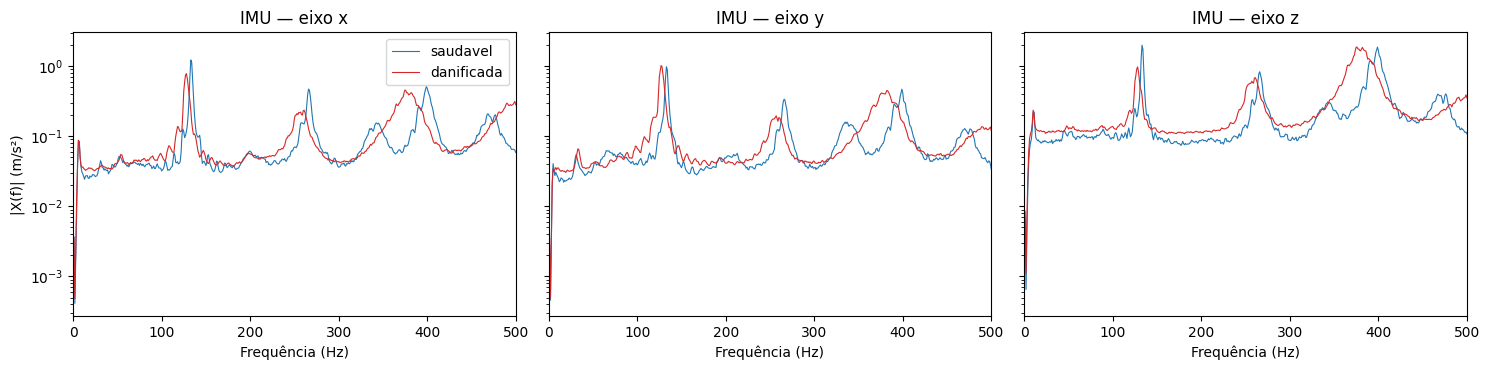

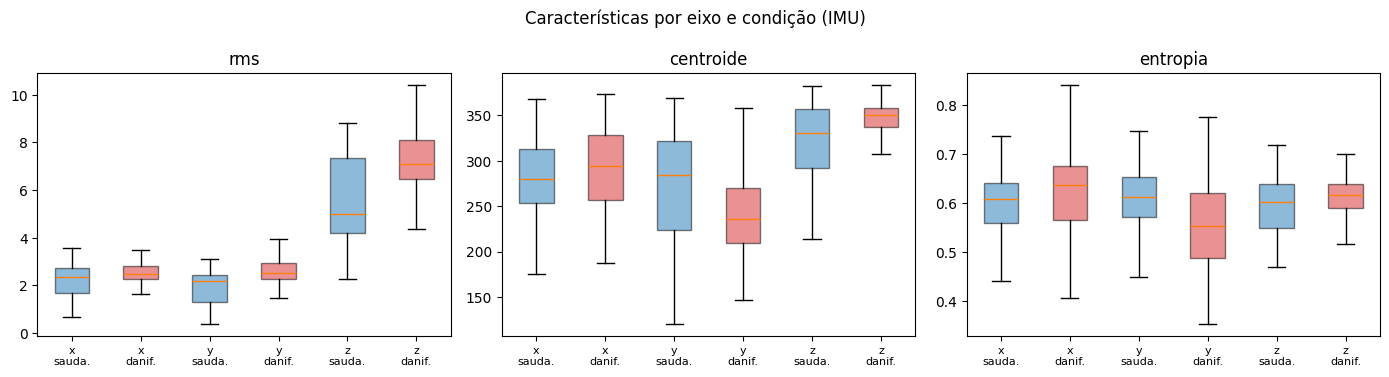

In [111]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, eixo in zip(axs, EIXOS):
    for cond in ['saudavel', 'danificada']:
        sel_e = ((df_imu.eixo == eixo) & (df_imu.condicao == cond)).values
        ax.semilogy(f_imu, espectros_imu[sel_e].mean(axis=0), color=CORES[cond], lw=0.8, label=cond)
    ax.set_title(f'IMU — eixo {eixo}'); ax.set_xlabel('Frequência (Hz)'); ax.set_xlim(0, FS_IMU / 2)
axs[0].set_ylabel('|X(f)| (m/s²)'); axs[0].legend()
plt.tight_layout(); plt.savefig('inv_espectros_eixos.pdf'); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axs, ['rms', 'centroide', 'entropia']):
    dados, rotulos, cores_box = [], [], []
    for eixo in EIXOS:
        for cond in ['saudavel', 'danificada']:
            dados.append(df_imu[(df_imu.eixo == eixo) & (df_imu.condicao == cond)][c])
            rotulos.append(f'{eixo}\n{cond[:5]}.'); cores_box.append(CORES[cond])
    bp = ax.boxplot(dados, patch_artist=True, showfliers=False)
    for caixa, cor in zip(bp['boxes'], cores_box): caixa.set_facecolor(cor); caixa.set_alpha(0.5)
    ax.set_xticks(range(1, len(rotulos) + 1), rotulos, fontsize=8); ax.set_title(c)
plt.suptitle('Características por eixo e condição (IMU)'); plt.tight_layout()
plt.savefig('inv_boxplots_eixos.pdf'); plt.show()

### **5.4 Resposta à pergunta**

Após o descarte de 101 janelas com motor parado (≈ 3,5% do total), foram analisadas 2 818 janelas: 237 saudáveis e 701–703 danificadas por eixo.

**Os eixos têm as mesmas características?** Não. Os três eixos registram vibrações com intensidades e distribuições espectrais diferentes:
- **Intensidade:** o eixo **z** vibra muito mais que os outros. Na condição saudável, o RMS é 5,50 m/s² em z, contra 2,27 m/s² em x e 1,96 m/s² em y, ou seja, 2,4 a 2,8 vezes maior.
- **Distribuição no espectro:** os três eixos apresentam os mesmos picos (≈ 130, ≈ 260 e ≈ 390–400 Hz), mas com pesos diferentes: em x e y, o pico mais forte é o de ≈ 130 Hz, enquanto em z o maior é o de ≈ 390–400 Hz. Por isso, o centroide espectral é mais alto em z (320 Hz no saudável) do que em x (281 Hz) e em y (273 Hz), e a frequência dominante média também é maior em z (≈ 303 Hz, contra ≈ 211 Hz em x e ≈ 228 Hz em y).
- **Componente média:** antes do filtro, só o eixo z tem média próxima da gravidade (≈ 9,7–9,8 m/s²); em x e y, a média é próxima de zero. Após o filtro, todas as características são calculadas sem essa componente.
- **Semelhanças:** o fator de crista (≈ 2,7–2,9) e a entropia espectral (≈ 0,56–0,62) têm valores parecidos nos três eixos.

**A diferença saudável × danificada aparece igualmente nos três eixos?** Também não. Pelo d de Cohen:
- **RMS:** o defeito aumenta a vibração nos três eixos, mas com intensidades diferentes: o efeito é grande em **z** (d = 1,42; RMS +33%) e **y** (d = 1,21; RMS +36%) e apenas médio em **x** (d = 0,58; RMS +12%).
- **Potência na banda B3 (335–500 Hz):** aumenta com o defeito nos três eixos, com efeito grande em todos (d = 1,48 em x, 0,97 em y e 1,44 em z). É o mesmo comportamento observado no piezo, em que a potência em B3 aumentou cerca de 70%: o aumento de energia nessa faixa aparece de forma consistente nos dois sensores.
- **Centroide e bandas inferiores:** mudam em direções diferentes conforme o eixo. Em y, o defeito aumenta a energia em B1 (d = 0,92) e reduz o centroide (d = −0,67) e a entropia (d = −0,62); em z, aumenta B2 (d = 0,58) e o centroide (d = 0,88); em x, essas medidas quase não mudam. A forma como o defeito altera o espectro depende da direção de medição.
- **Fator de crista:** praticamente não diferencia as condições (|d| ≤ 0,38, com leve redução em z).

**Comparação com o piezo:** os três eixos da IMU apresentam as mesmas componentes principais encontradas no piezo (seção 5.1). Além disso, nos três eixos, os picos da condição danificada aparecem em frequências ligeiramente menores que os da saudável, o mesmo deslocamento observado no piezo (133 → 128 Hz e 400 → ≈ 380 Hz), o que indica que esse efeito é uma característica do sinal, e não do sensor. Na IMU, porém, a banda B3 fica perto do limite de Nyquist (500 Hz), e parte da energia medida pode vir de componentes acima de 500 Hz rebatidas por aliasing (seção 5.1); por isso, os valores de B3 da IMU devem ser interpretados com cautela.

**Conclusão:** as vibrações nos eixos X, Y e Z **não têm as mesmas características**: o eixo z vibra de 2,4 a 2,8 vezes mais e concentra mais energia na componente de ≈ 400 Hz. O defeito se manifesta nos três eixos como aumento da energia na banda de 335–500 Hz e como um leve deslocamento dos picos para frequências menores, mas com intensidade diferente: o aumento do RMS é grande em z e y e médio em x, e o centroide muda em sentidos opostos entre os eixos. Para detectar o defeito com a IMU, **o eixo z seria o mais útil**, por ter os maiores efeitos no RMS (d = 1,42), na banda B3 (d = 1,44) e no centroide (d = 0,88).